# Lab: Online Machine Learning with River and CapyMOA

**Ghamgui Nour , M2 Data Science**




---
# Part 1: River

## Step 1


In [51]:
!pip install river

In [2]:
import time, random, pickle, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from river import (compose, datasets, drift, evaluate, forest, linear_model,
                   metrics, multiclass, naive_bayes, neighbors, optim,
                   preprocessing, stats, tree)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 160, "display.max_columns", 30)

In [3]:
#  Chart styling: fixed categorical palette (one color = one method)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9.5,
    "legend.frameon": False, "figure.dpi": 110, "lines.linewidth": 1.8,
})

def color_map(names):
    """One fixed color per entity (method), assigned in order"""
    assert len(names) <= len(PALETTE), "not enough colours in PALETTE"
    return {n: PALETTE[i] for i, n in enumerate(names)}


Everything that follows relies on the prequential function which implements test-then-train and additionally records:

- the running metrics (updated once per observation)
- the model time (predict_one + learn_one, excluding metrics) → per-instance latency in microseconds
- the total loop runtime (runtime_s)
- the end-of-stream model size, estimated via the size of its pickle serialization (a reasonable approximation of the model's memory footprint, far less expensive than tracemalloc, which would heavily slow down execution)
- the per-instance error series (useful for plotting rolling curves and analyzing concept drift).

 The check below uses skip_first=0 to match River exactly.




In [4]:
def make_metrics(task):
    if task == "reg":
        return {"MAE": metrics.MAE(), "RMSE": metrics.RMSE(), "R2": metrics.R2()}
    return {"Accuracy": metrics.Accuracy(), "MacroF1": metrics.MacroF1(), "Kappa": metrics.CohenKappa()}


def prequential(model, stream, task, skip_first=None):
    if skip_first is None:
        skip_first = 1 if task == "reg" else 0
    mets = make_metrics(task)
    errs, t_model, n = [], 0.0, 0
    t_start = time.perf_counter()
    for x, y in stream:
        t0 = time.perf_counter()
        y_pred = model.predict_one(x)          # 1) TEST
        t1 = time.perf_counter()
        model.learn_one(x, y)                  # 2) TRAIN
        t_model += time.perf_counter() - t0
        if y_pred is None or n < skip_first:   # No exploitable prediction
            errs.append(np.nan)
        else:
            for m in mets.values():
                m.update(y, y_pred)
            errs.append(abs(y - y_pred) if task == "reg" else float(y_pred != y))
        n += 1
    runtime = time.perf_counter() - t_start
    try:
        size_kb = len(pickle.dumps(model)) / 1024 # model size
    except Exception:
        size_kb = np.nan
    out = {k: m.get() for k, m in mets.items()}
    out.update(n=n, runtime_s=runtime, latency_us=1e6 * t_model / n, size_kb=size_kb)
    return out, np.array(errs), model

## Step 2  Regression methods and datasets

### 2.1 The 4 regression methods

| Type | River method |
|---|---|
| **Tree** | `HoeffdingTreeRegressor` |
| **Ensemble** | `forest.ARFRegressor` (*Adaptive Random Forest*) |
| **Linear with adaptive step size** | `LinearRegression` + `optim.Adam` |
| **Other (our choice)** | `neighbors.KNNRegressor` |

**Model-specific preprocessing.** Each model receives the preprocessing it actually needs (defined in `REG_PREP`, in the next cell). Three building blocks are available: an online `StandardScaler` on the numeric features, a `OneHotEncoder` on the categorical features, and a `TargetStandardScaler` on the target `y` (the model learns `(y − μ)/σ` and its predictions are converted back).

| Model | Numeric `X` | Categorical `X` | `y` | Why |
|---|---|---|---|---|
| `HoeffdingTreeRegressor` | standardised | one-hot | standardised | The choice of splits does not depend on scale, **but the default leaf is a linear model based on the observations ** trained by gradient descent, which is very sensitive to the scale of `X` and `y`. `chick` and `diet`for example are *identifiers*, not quantities: treated as numbers, the tree could only cut them as "≤ threshold"; one-hot encoded, it can isolate one chick or one diet. |
| `ARFRegressor` | standardised | one-hot | standardised | Its trees are Hoeffding trees: same needs. |
| `LinearRegression` + Adam | standardised | one-hot | standardised | Stochastic gradient descent: features on very different scales make a single learning rate inappropriate; the intercept starts at 0, hence the benefit of centring `y`. One-hot encoding gives each chick/diet its own coefficient. |
| `KNNRegressor` | standardised | one-hot | **not scaled** | Euclidean distance: without standardisation, the feature with the largest scale dominates the others; one-hot encoding avoids inventing an order between chicks. `y` plays no part in the distance and the prediction is the mean of the neighbours' `y`, so scaling it would be meaningless as preprocessing (an online scaler would only act as a side-effect detrending, by storing targets relative to the current level of `y`). |


### 2.2 The 4 datasets



| Dataset | Nature | Size |
|---|---|---|
| `TrumpApproval` | **real** | 1,001 |
| `ChickWeights` | **real** | 578 |
| `SP500Stocks` | **real** | 1,257 |
| `FriedmanDrift` | **synthetic** | 10,000 (ours) |

The synthetic dataset has drifts at known positions

In [5]:
N_FRIEDMAN = 10_000
FRIEDMAN_DRIFTS = (4_000, 7_000)

REG_DATASETS = {
    "TrumpApproval": dict(make=lambda: datasets.TrumpApproval(),  cat=[]),
    "ChickWeights":  dict(make=lambda: datasets.ChickWeights(),   cat=["chick", "diet"]),
    "SP500Stocks":   dict(make=lambda: datasets.SP500Stocks(),    cat=[]),
    "FriedmanDrift": dict(make=lambda: datasets.synth.FriedmanDrift(
                              drift_type="gra", position=FRIEDMAN_DRIFTS, seed=SEED).take(N_FRIEDMAN), cat=[]),
}
for name, d in REG_DATASETS.items():
    x0, _ = next(iter(d["make"]()))
    d["num"] = [k for k in x0 if k not in d["cat"]]

# Dataset overview
rows = []
for name, d in REG_DATASETS.items():
    ys = np.array([y for _, y in d["make"]()])
    rows.append(dict(dataset=name, n=len(ys), n_features=len(d["num"]) + len(d["cat"]),
                     y_mean=ys.mean(), y_std=ys.std(), y_min=ys.min(), y_max=ys.max()))
pd.DataFrame(rows).set_index("dataset").round(3)

,n,n_features,y_mean,y_std,y_min,y_max
dataset,,,,,,
TrumpApproval,1001,6,40.755,1.711,36.403,44.767
ChickWeights,578,3,121.818,71.010,35.000,373.000
SP500Stocks,1257,10,0.056,0.781,-4.095,4.829
FriedmanDrift,10000,10,14.438,4.941,-0.697,28.773


In [6]:
REG_MODELS = ["HoeffdingTree", "ARF", "LinReg-Adam", "KNN"]   # order = order of the colours

REG_PREP = {
    "HoeffdingTree":         dict(scale_x=True, onehot=True, scale_y=True),
    "ARF":                   dict(scale_x=True, onehot=True, scale_y=True),
    "LinReg-Adam":           dict(scale_x=True, onehot=True, scale_y=True),
    "KNN":                   dict(scale_x=True, onehot=True, scale_y=False),
}

REG_CORES = {
    "HoeffdingTree":         lambda: tree.HoeffdingTreeRegressor(),
    "ARF":                   lambda: forest.ARFRegressor(n_models=10, seed=SEED),
    "LinReg-Adam":           lambda: linear_model.LinearRegression(optimizer=optim.Adam(lr=0.01)),
    "KNN":                   lambda: neighbors.KNNRegressor(n_neighbors=5, engine=neighbors.LazySearch(window_size=200)),
}

def prep(num, cat, scale_x, onehot):
    """Preprocessing of X """
    pipe = compose.Select(*num) | preprocessing.StandardScaler() if scale_x else compose.Select(*num)
    if cat:
        pipe = pipe + (compose.Select(*cat) | preprocessing.OneHotEncoder() if onehot else compose.Select(*cat))
    return pipe

def make_reg_model(name, num, cat):
    """Model-specific pipeline: preprocessing of X (according to REG_PREP[name]) -> regressor, optionally wrapped in a TargetStandardScaler (standardization of y)"""
    p, core = REG_PREP[name], REG_CORES[name]()
    if p["scale_y"]:
        core = preprocessing.TargetStandardScaler(regressor=core)
    return prep(num, cat, p["scale_x"], p["onehot"]) | core

REG_COLORS = color_map(REG_MODELS)

**Verification**

In [7]:
d = REG_DATASETS["TrumpApproval"]
ours, _, _ = prequential(make_reg_model("HoeffdingTree", d["num"], d["cat"]), d["make"](), "reg", skip_first=0)

ref = evaluate.progressive_val_score(
    dataset=d["make"](), model=make_reg_model("HoeffdingTree", d["num"], d["cat"]),
    metric=metrics.MAE(), print_every=0)

print(f"MAE (our loop)                  : {ours['MAE']:.6f}")
print(f"MAE (progressive_val_score River): {ref.get():.6f}")
assert abs(ours["MAE"] - ref.get()) < 1e-9

MAE (our loop)                  : 0.391332
MAE (progressive_val_score River): 0.391332


## Step 3 : Comparison of the 4 methods across the 4 datasets

We run all 16 combinations (method × dataset) using the prequential protocol. Each run starts from a fresh model and a fresh stream (using the same random seeds)






In [8]:
reg_rows, reg_errs = [], {}
for ds_name, d in REG_DATASETS.items():
    for m_name in REG_MODELS:
        model = make_reg_model(m_name, d["num"], d["cat"])
        res, errs, _ = prequential(model, d["make"](), "reg")
        reg_rows.append(dict(dataset=ds_name, model=m_name, **res))
        reg_errs[(ds_name, m_name)] = errs
df_reg = pd.DataFrame(reg_rows)
print("OK :", len(df_reg), "executions")

OK : 16 executions


In [9]:
def pivot(df, col, fmt="{:.3f}", best="min"):
    p = df.pivot(index="dataset", columns="model", values=col).loc[list(REG_DATASETS), REG_MODELS]
    return (p.style.highlight_min if best == "min" else p.style.highlight_max)(axis=1, color="#cde2fb").format(fmt)

print("MAE ")
pivot(df_reg, "MAE")

MAE 


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,0.348,0.329,0.470,0.502
ChickWeights,20.655,18.304,16.542,26.388
SP500Stocks,0.574,0.575,0.588,0.619
FriedmanDrift,1.981,2.421,2.165,2.628


In [10]:
print("RMSE ")
pivot(df_reg, "RMSE")

RMSE 


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,0.456,0.475,0.603,0.675
ChickWeights,32.462,27.824,26.027,36.943
SP500Stocks,0.803,0.803,0.817,0.846
FriedmanDrift,2.584,3.117,2.786,3.289


In [11]:
print("R² ")
pivot(df_reg, "R2", best="max")

R² 


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,0.929,0.923,0.875,0.844
ChickWeights,0.791,0.846,0.866,0.729
SP500Stocks,-0.056,-0.054,-0.092,-0.171
FriedmanDrift,0.727,0.602,0.682,0.557


In [12]:
print("Per instance latency,  µs (predict_one + learn_one)")
pivot(df_reg, "latency_us", "{:,.0f}")

Per instance latency,  µs (predict_one + learn_one)


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,181,"4,608",32,91
ChickWeights,195,"1,136",132,814
SP500Stocks,183,"2,767",40,135
FriedmanDrift,197,"3,592",41,148


In [13]:
print("Total loop runtime, in seconds")
pivot(df_reg, "runtime_s", "{:,.2f}")

Total loop runtime, in seconds


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,0.21,4.72,0.04,0.11
ChickWeights,0.12,0.67,0.09,0.48
SP500Stocks,0.25,3.53,0.07,0.19
FriedmanDrift,2.08,36.19,0.51,1.60


In [14]:
print("End-of-stream model size, in KB (pickle serialization)")
pivot(df_reg, "size_kb", "{:,.0f}")

End-of-stream model size, in KB (pickle serialization)


model,HoeffdingTree,ARF,LinReg-Adam,KNN
dataset,,,,
TrumpApproval,17,292,2,17
ChickWeights,18,170,5,49
SP500Stocks,82,"1,226",2,26
FriedmanDrift,512,"9,586",2,26


### Visualisations

The plots use a fixed color per method. The MAE axis is specific to each dataset, as the targets have different scales.

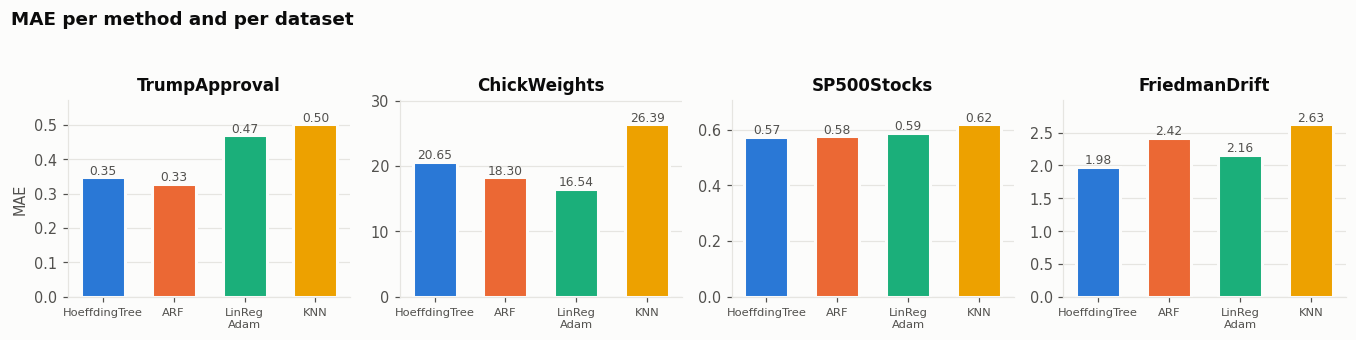

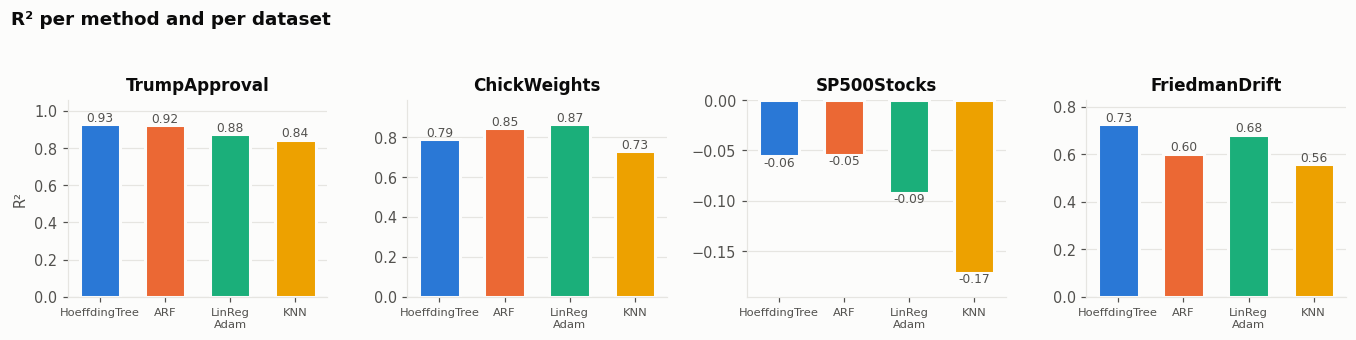

In [15]:
def bar_panels(df, metric, models, colors, ds_names, ylabel, title, floor=None):
    fig, axes = plt.subplots(1, len(ds_names), figsize=(3.1 * len(ds_names), 3.1), sharey=False)
    for ax, ds in zip(axes, ds_names):
        sub = df[df.dataset == ds].set_index("model").loc[models]
        vals = sub[metric].values
        shown = np.clip(vals, floor, None) if floor is not None else vals
        ax.bar(range(len(models)), shown, color=[colors[m] for m in models], width=0.62,
               edgecolor=SURFACE, linewidth=2)
        for i, (v, s) in enumerate(zip(vals, shown)):
            ax.text(i, s, f"{v:.2f}" if abs(v) < 100 else f"{v:.0f}", ha="center",
                    va="bottom" if s >= 0 else "top", fontsize=8, color=INK2)
        ax.set_xticks(range(len(models)))
        ax.set_xticklabels([m.replace("-", "\n") for m in models], fontsize=7.5)
        ax.set_title(ds); ax.grid(axis="x", visible=False); ax.margins(y=0.14)
        if ax is axes[0]: ax.set_ylabel(ylabel)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

bar_panels(df_reg, "MAE", REG_MODELS, REG_COLORS, list(REG_DATASETS), "MAE", "MAE per method and per dataset ")
bar_panels(df_reg, "R2", REG_MODELS, REG_COLORS, list(REG_DATASETS), "R²", "R² per method and per dataset ", floor=-1)

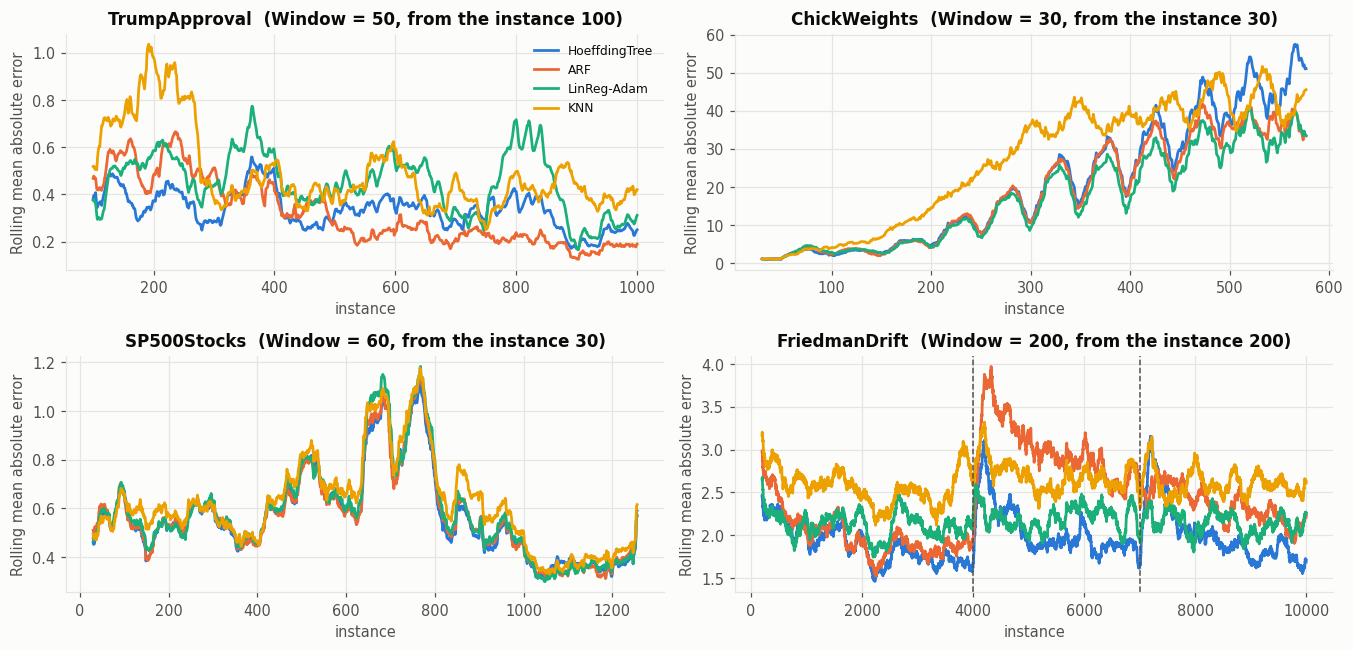

In [16]:
def rolling_panels(errs, ds_names, models, colors, windows, starts, ylabel, true_drifts=None, to_acc=False, ncols=2):
    """Rolling curves; the first `starts[ds]` instances (warm-up, dominated by the start-up error) are masked."""
    nrows = int(np.ceil(len(ds_names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 3.0 * nrows))
    for ax, ds in zip(np.ravel(axes), ds_names):
        for m in models:
            e = pd.Series(errs[(ds, m)])
            s = (1 - e) if to_acc else e
            r = s.rolling(windows[ds], min_periods=1).mean()
            ax.plot(r.index[starts[ds]:], r.values[starts[ds]:], color=colors[m], label=m)
        for p in (true_drifts or {}).get(ds, []):
            ax.axvline(p, color=INK2, ls="--", lw=1)
        ax.set_title(f"{ds}  (Window = {windows[ds]}, from the instance {starts[ds]})"); ax.set_xlabel("instance")
        ax.set_ylabel(ylabel)
    for ax in np.ravel(axes)[len(ds_names):]: ax.axis("off")
    np.ravel(axes)[0].legend(loc="best", fontsize=8)
    fig.tight_layout(); plt.show()

REG_WINDOWS = {"TrumpApproval": 50, "ChickWeights": 30, "SP500Stocks": 60, "FriedmanDrift": 200}
REG_STARTS  = {"TrumpApproval": 100, "ChickWeights": 30, "SP500Stocks": 30, "FriedmanDrift": 200}
rolling_panels(reg_errs, list(REG_DATASETS), REG_MODELS, REG_COLORS, REG_WINDOWS, REG_STARTS,
               "Rolling mean absolute error", true_drifts={"FriedmanDrift": FRIEDMAN_DRIFTS})

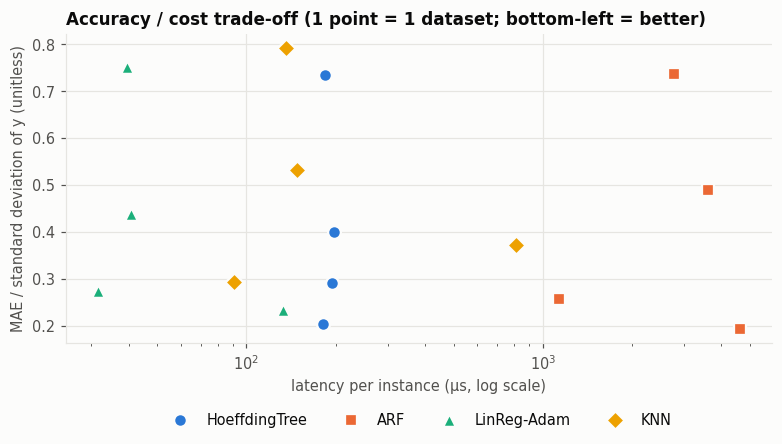

In [17]:
# Accuracy / cost trade-off: normalized error (MAE / standard deviation of y) vs. latency (log scale)
sd_y = {n: np.std([y for _, y in d["make"]()]) for n, d in REG_DATASETS.items()}
markers = dict(zip(REG_MODELS, ["o", "s", "^", "D"]))
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for m in REG_MODELS:
    sub = df_reg[df_reg.model == m]
    ax.scatter(sub.latency_us, sub.MAE / sub.dataset.map(sd_y), s=70, marker=markers[m], color=REG_COLORS[m],
               edgecolor=SURFACE, linewidth=1.5, label=m, zorder=3)
ax.set_xscale("log"); ax.set_xlabel("latency per instance (µs, log scale)")
ax.set_ylabel("MAE / standard deviation of y (unitless)")
ax.set_title("Accuracy / cost trade-off (1 point = 1 dataset; bottom-left = better)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4); fig.tight_layout(); plt.show()

## Step 4 : Drift detection (regression)


| Detector |
|---|
| **ADWIN** |
| **Page-Hinkley (PH)** |
| **KSWIN** (**Kolmogorov-Smirnov**) |

**One-sided alerts (error increases only).**  `ResetOnDrift` triggered about thirty resets on `FriedmanDrift`: the high error of the fresh model, then its decrease, were very likely mistaken for new drifts, and the model never had time to learn. The wrapper therefore also resets the detector after each model reset. We keep only the **increases**:
- `PageHinkley(mode="up")`: native;
- ADWIN and KSWIN (two-sided): the `OneSided` wrapper compares the mean level of the detector's internal window before and after the alert and ignores decreases;
- in classification, DDM, EDDM and HDDM are already one-sided (they react to more errors); only ADWIN is wrapped.

**For a real dataset**, the position of the true drifts is unknown: we can only count the alerts and look at where they fall.

### 4.1 Detection metrics (synthetic dataset)

On `FriedmanDrift`, the drifts are at **t = 4,000** and **t = 7,000**. Each true drift is matched with the **first alert** in the window `[t, t + 1,000]`; the **detection delay** is the gap in instances. A drift with no alert in this window is **missed**; any alert not matched to a true drift is a **false alarm**.

### 4.2 Step A :detection only (fair comparison)

A **single** base model (`HoeffdingTreeRegressor`, left to learn normally, without reacting to the alerts) produces **one** error stream, which the three detectors observe *simultaneously*. They therefore receive exactly the same data.

In [18]:
class OneSided:
    """Makes a two-sided detector sensitive only to INCREASES in the monitored signal (here, the error).
    At each alert, the average level of the detector's internal window is compared just before and just after
    the update: if the level has decreased, the alert is ignored (the model is simply learning)."""
    def __init__(self, det):
        self.det, self.drift_detected = det, False

    def _level(self):
        if isinstance(self.det, drift.ADWIN):
            return self.det.estimation
        w = list(self.det.window)                       # KSWIN
        return float(np.mean(w)) if w else 0.0

    def update(self, e):
        before = self._level()
        self.det.update(e)
        up = (self._level() > before) if self.det.drift_detected else False
        self.drift_detected = bool(self.det.drift_detected and up)

DET_REG = {"ADWIN":       lambda: OneSided(drift.ADWIN()),
           "PageHinkley": lambda: drift.PageHinkley(mode="up"),
           "KSWIN":       lambda: OneSided(drift.KSWIN(seed=SEED))}
DET_COLORS_REG = color_map(list(DET_REG))

def norm_error(y, y_pred, var):
    sd = var.get() ** 0.5 if var.n > 2 else 1.0
    return abs(y - y_pred) / (sd or 1.0)

def detect_only(task, make_stream, model, det_factories):
    """One model, one shared error stream, multiple detectors. Returns alert positions."""
    dets = {k: f() for k, f in det_factories.items()}
    pos = {k: [] for k in dets}
    var, t = stats.Var(), 0
    for x, y in make_stream():
        y_pred = model.predict_one(x)
        model.learn_one(x, y)
        if y_pred is not None and (task == "clf" or var.n >= 1):     # skip prediction from the untrained model
            e = norm_error(y, y_pred, var) if task == "reg" else int(y_pred != y)
            for k, det in dets.items():
                det.update(e)
                if det.drift_detected:
                    pos[k].append(t)
        if task == "reg":
            var.update(y)
        t += 1
    return pos

def score_detection(positions, true_drifts, tol):
    """Detection delay per true drift (None = missed) and list of false alarms"""
    delays, matched = {}, set()
    for p in true_drifts:
        hits = [d for d in positions if p <= d <= p + tol]
        delays[p] = hits[0] - p if hits else None
        if hits: matched.add(hits[0])
    return delays, [d for d in positions if d not in matched]

In [19]:
base_reg = lambda d: make_reg_model("HoeffdingTree", d["num"], d["cat"])
reg_detect = {ds: detect_only("reg", d["make"], base_reg(d), DET_REG) for ds, d in REG_DATASETS.items()}

# --- reel datasets : number and positions of the alerts---
rows = []
for ds in ["TrumpApproval", "ChickWeights", "SP500Stocks"]:
    for det, pos in reg_detect[ds].items():
        rows.append(dict(dataset=ds, n_instances=sum(1 for _ in REG_DATASETS[ds]["make"]()),
                         detector=det, n_alerts=len(pos), positions=pos))
pd.DataFrame(rows).set_index(["dataset", "detector"])

n_instances  n_alerts positions
dataset       detector                                    
TrumpApproval ADWIN               1001         0        []
              PageHinkley         1001         0        []
              KSWIN               1001         1     [837]
ChickWeights  ADWIN                578         0        []
              PageHinkley          578         0        []
              KSWIN                578         0        []
SP500Stocks   ADWIN               1257         0        []
              PageHinkley         1257         1     [666]
              KSWIN               1257         1     [436]

In [20]:
# --- Synthetic dataset : positions, delays,false alarms ---
TOL_REG = 1_000
rows = []
for det, pos in reg_detect["FriedmanDrift"].items():
    delays, fa = score_detection(pos, FRIEDMAN_DRIFTS, TOL_REG)
    rows.append({"detector": det, "n_alarms": len(pos),
                 f"drift delay @{FRIEDMAN_DRIFTS[0]}": delays[FRIEDMAN_DRIFTS[0]],
                 f"drift delay @{FRIEDMAN_DRIFTS[1]}": delays[FRIEDMAN_DRIFTS[1]],
                 "missed drifts": sum(v is None for v in delays.values()),
                 "false alarms": len(fa), "positions": pos})
pd.DataFrame(rows).set_index("detector")

,n_alarms,drift delay @4000,drift delay @7000,missed drifts,false alarms,positions
detector,,,,,,
ADWIN,2,32,40,0,0,"[4032, 7040]"
PageHinkley,2,201,224,0,0,"[4201, 7224]"
KSWIN,13,17,19,0,11,"[840, 1794, 2430, 3077, 3361, 4017, 4642, 5772..."


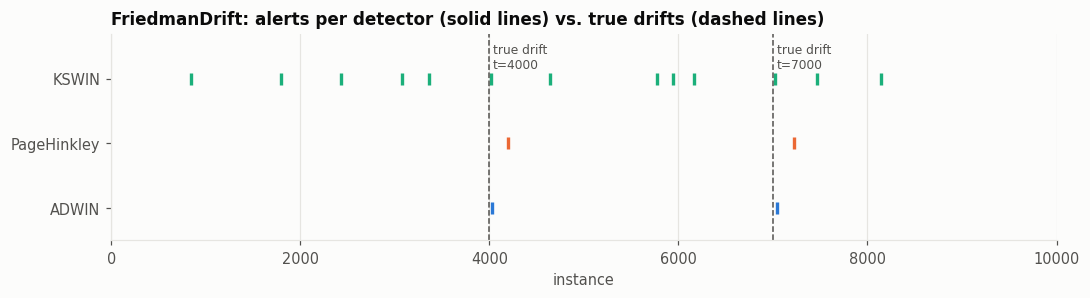

In [21]:
# Visualisation: where did each detector fire on FriedmanDrift?
fig, ax = plt.subplots(figsize=(10, 2.8))
for i, (det, pos) in enumerate(reg_detect["FriedmanDrift"].items()):
    ax.scatter(pos, [i] * len(pos), s=70, marker="|", linewidths=2.2, color=DET_COLORS_REG[det])
for p in FRIEDMAN_DRIFTS:
    ax.axvline(p, color=INK2, ls="--", lw=1); ax.text(p + 40, len(DET_REG) - 0.45, f"true drift\nt={p}", fontsize=8, color=INK2, va="top")
ax.set_yticks(range(len(DET_REG))); ax.set_yticklabels(list(DET_REG)); ax.set_ylim(-0.5, len(DET_REG) - 0.3)
ax.set_xlim(0, N_FRIEDMAN); ax.set_xlabel("instance"); ax.grid(axis="y", visible=False)
ax.set_title("FriedmanDrift: alerts per detector (solid lines) vs. true drifts (dashed lines)", loc="left")
fig.tight_layout(); plt.show()

### 4.4 Step B : effect of drift handling on performance

The `ResetOnDrift` wrapper monitors the error stream with a detector and, at each alert, **replaces the model with a fresh one** (relearning from scratch on the recent data, preprocessing included). We compare, using the same base model (`HoeffdingTreeRegressor`):

- **no handling** (baseline);
- **+ ADWIN**, **+ Page-Hinkley**, **+ KSWIN** (reset at each alert);


In [22]:
class ResetOnDrift:
    """Model + detector: on each alert, both the model AND the detector are reset (retrained from scratch).
    Compatible with regression (normalized absolute error) and classification (0/1 error)."""
    def __init__(self, factory, det_factory, task):
        self.factory, self.det_factory, self.task = factory, det_factory, task
        self.model, self.detector = factory(), det_factory()
        self.var, self.t, self.positions, self._pred = stats.Var(), 0, [], None

    def predict_one(self, x):
        self._pred = self.model.predict_one(x)
        return self._pred

    def learn_one(self, x, y):
        if self._pred is not None and (self.task == "clf" or self.var.n >= 1):
            e = norm_error(y, self._pred, self.var) if self.task == "reg" else int(self._pred != y)
            self.detector.update(e)
            if self.detector.drift_detected:
                self.positions.append(self.t)
                self.model = self.factory()            #reset
                self.detector = self.det_factory()
        if self.task == "reg": self.var.update(y)
        self.model.learn_one(x, y)
        self.t += 1

def segment_scores(err, bounds, task):
    """Average error (MAE) or accuracy per segment [b0, b1), [b1, b2), ..."""
    e, edges, out = np.asarray(err, float), [0, *bounds, len(err)], []
    for a, b in zip(edges[:-1], edges[1:]):
        seg = e[a:b]; seg = seg[~np.isnan(seg)]
        out.append(seg.mean() if task == "reg" else 1 - seg.mean())
    return out

In [23]:
REG_VARIANTS = ["HT (no handling)", "HT + ADWIN", "HT + PageHinkley", "HT + KSWIN"]
REG_VAR_COLORS = color_map(REG_VARIANTS)

def reg_variant(name, d):
    fac = lambda: make_reg_model("HoeffdingTree", d["num"], d["cat"])
    if name == "HT (no handling)": return fac()
    det = {"HT + ADWIN": "ADWIN", "HT + PageHinkley": "PageHinkley", "HT + KSWIN": "KSWIN"}[name]
    return ResetOnDrift(fac, DET_REG[det], "reg")

rows, reg_var_errs, reg_resets = [], {}, {}
for ds, d in REG_DATASETS.items():
    for v in REG_VARIANTS:
        model = reg_variant(v, d)
        res, errs, model = prequential(model, d["make"](), "reg")
        res.pop("size_kb")
        n_reset = len(model.positions) if isinstance(model, ResetOnDrift) else np.nan
        reg_resets[(ds, v)] = model.positions if isinstance(model, ResetOnDrift) else []
        rows.append(dict(dataset=ds, variante=v, n_resets=n_reset, **res))
        reg_var_errs[(ds, v)] = errs
df_reg_var = pd.DataFrame(rows)

def pivot_var(df, col, variants, ds_list, fmt="{:.3f}", best="min"):
    p = df.pivot(index="dataset", columns="variante", values=col).loc[ds_list, variants]
    return (p.style.highlight_min if best == "min" else p.style.highlight_max)(axis=1, color="#cde2fb").format(fmt)

print("MAE depending on drift handling ")
pivot_var(df_reg_var, "MAE", REG_VARIANTS, list(REG_DATASETS))

MAE depending on drift handling 


variante,HT (no handling),HT + ADWIN,HT + PageHinkley,HT + KSWIN
dataset,,,,
TrumpApproval,0.348,0.348,0.348,0.347
ChickWeights,20.655,20.655,20.655,20.655
SP500Stocks,0.574,0.574,0.576,0.583
FriedmanDrift,1.981,2.031,2.051,2.146


In [24]:
print("Number of resets triggered by the detector")
pivot_var(df_reg_var, "n_resets", REG_VARIANTS[1:4], list(REG_DATASETS), "{:.0f}")

Number of resets triggered by the detector


variante,HT + ADWIN,HT + PageHinkley,HT + KSWIN
dataset,,,
TrumpApproval,0,0,2
ChickWeights,0,0,0
SP500Stocks,0,1,2
FriedmanDrift,1,1,6


In [25]:
print("R² ")
pivot_var(df_reg_var, "R2", REG_VARIANTS, list(REG_DATASETS), best="max")

R² 


variante,HT (no handling),HT + ADWIN,HT + PageHinkley,HT + KSWIN
dataset,,,,
TrumpApproval,0.929,0.929,0.929,0.929
ChickWeights,0.791,0.791,0.791,0.791
SP500Stocks,-0.056,-0.056,-0.062,-0.097
FriedmanDrift,0.727,0.719,0.709,0.684


In [26]:
# Zoom in on FriedmanDrift: MAE per segment (before drift 1 / between both drifts / after drift 2)
seg = {v: segment_scores(reg_var_errs[("FriedmanDrift", v)], FRIEDMAN_DRIFTS, "reg") for v in REG_VARIANTS}
labels = [f"[0, {FRIEDMAN_DRIFTS[0]})", f"[{FRIEDMAN_DRIFTS[0]}, {FRIEDMAN_DRIFTS[1]})", f"[{FRIEDMAN_DRIFTS[1]}, {N_FRIEDMAN})"]
print("FriedmanDrift: average MAE per segment")
pd.DataFrame(seg, index=labels).T.style.format("{:.3f}")

FriedmanDrift: average MAE per segment


,"[0, 4000)","[4000, 7000)","[7000, 10000)"
HT (no handling),1.898,2.048,2.023
HT + ADWIN,1.898,2.233,2.004
HT + PageHinkley,1.898,2.201,2.105
HT + KSWIN,2.077,2.146,2.239


FriedmanDrift: reset positions (true drifts: 4000 and 7000)
  HT + ADWIN         [4032]
  HT + PageHinkley   [4201]
  HT + KSWIN         [840, 4033, 7041, 7452, 7989, 9360]


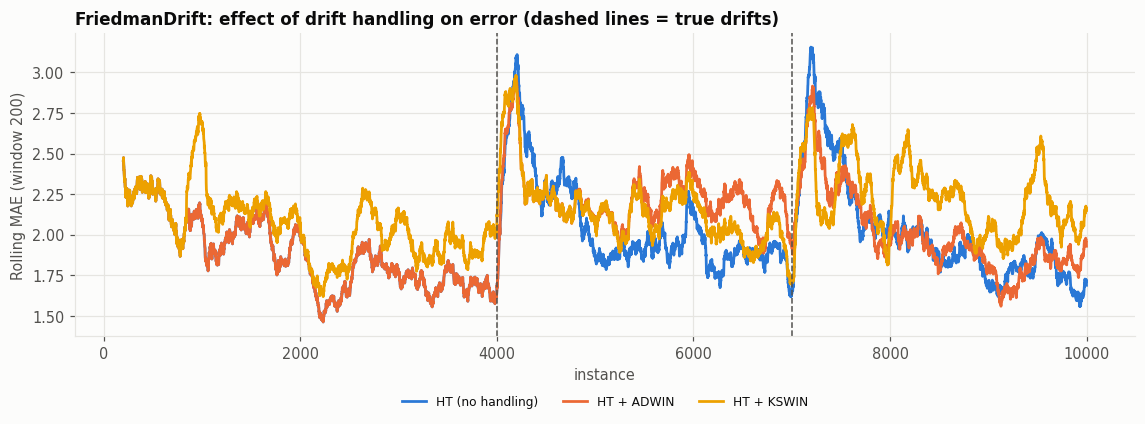

In [27]:
print("FriedmanDrift: reset positions (true drifts: 4000 and 7000)")
for v in REG_VARIANTS[1:4]:
    print(f"  {v:18s}", reg_resets[("FriedmanDrift", v)])

# Rolling MAE on FriedmanDrift, with the true drifts (dashed) and the resets (triangles)
fig, ax = plt.subplots(figsize=(10.5, 4.0))
for v in ["HT (no handling)", "HT + ADWIN", "HT + KSWIN"]:     # 3 readable variants
    s = pd.Series(reg_var_errs[("FriedmanDrift", v)]).rolling(200, min_periods=1).mean()
    ax.plot(s.index[200:], s.values[200:], color=REG_VAR_COLORS[v], label=v)
for p in FRIEDMAN_DRIFTS: ax.axvline(p, color=INK2, ls="--", lw=1)
ax.set_xlabel("instance"); ax.set_ylabel("Rolling MAE (window 200)")
ax.set_title("FriedmanDrift: effect of drift handling on error (dashed lines = true drifts)", loc="left")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16)); fig.tight_layout(); plt.show()

## Step 5 : Classification (repeating steps 2 to 4)

We repeat the same approach for classification: 4 methods, 3 real datasets, 1 synthetic dataset, Accuracy / Macro-F1 / Kappa metrics, and detectors adapted to **binary** error streams (whether the classifier was wrong or not).

### 5.1 The 4 classification methods

| Type | River Method |
|---|---|
| **Tree** | `HoeffdingTreeClassifier` |
| **Ensemble** | `forest.ARFClassifier` |
| **Linear with adaptive step size** | `LogisticRegression` + `optim.Adam` |
| **Other** | `naive_bayes.GaussianNB` |

### 5.2 The 4 datasets

| Dataset | Nature | Size |
|---|---|---|
| `Phishing` | **real** | 1,250 |
| `ImageSegments` | **real** | 2,310 |
| `Shuttle` | **real** | 49,097 |
| `SEA + drift` | **synthetic** | 20,000 |


In [28]:
N_SEA, SEA_DRIFT = 20_000, 10_000
make_sea = lambda: datasets.synth.ConceptDriftStream(
    datasets.synth.SEA(variant=0, noise=0.1, seed=SEED), datasets.synth.SEA(variant=3, noise=0.1, seed=SEED),
    position=SEA_DRIFT, width=100, seed=SEED).take(N_SEA)

CLF_DATASETS = {
    "Phishing":      dict(make=lambda: datasets.Phishing(),      binary=True),
    "ImageSegments": dict(make=lambda: datasets.ImageSegments(), binary=False),
    "Shuttle":       dict(make=lambda: datasets.Shuttle(),       binary=True),
    "SEA+drift":     dict(make=make_sea,                          binary=True),
}
CLF_MODELS = ["HoeffdingTree", "ARF", "LogReg-Adam", "GaussianNB"]
CLF_COLORS = color_map(CLF_MODELS)

CLF_PREP = {
    "HoeffdingTree": dict(scale_x=False),
    "ARF":           dict(scale_x=False),
    "GaussianNB":    dict(scale_x=False),
    "LogReg-Adam":   dict(scale_x=True),
}

def make_clf_model(name, binary):
    if name == "HoeffdingTree": core = tree.HoeffdingTreeClassifier()
    elif name == "ARF":         core = forest.ARFClassifier(n_models=10, seed=SEED)
    elif name == "GaussianNB":  core = naive_bayes.GaussianNB()
    elif name == "LogReg-Adam":
        lr = linear_model.LogisticRegression(optimizer=optim.Adam(lr=0.01))
        core = lr if binary else multiclass.OneVsRestClassifier(lr)
    else:
        raise ValueError(name)
    return preprocessing.StandardScaler() | core if CLF_PREP[name]["scale_x"] else core

import collections
rows = []
for name, d in CLF_DATASETS.items():
    ys = [y for _, y in d["make"]()]; x0, _ = next(iter(d["make"]()))
    c = collections.Counter(ys)
    rows.append(dict(dataset=name, n=len(ys), n_features=len(x0), n_classes=len(c),
                     proportion_classe_majoritaire=max(c.values()) / len(ys)))
pd.DataFrame(rows).set_index("dataset").round(3)

,n,n_features,n_classes,proportion_classe_majoritaire
dataset,,,,
Phishing,1250,9,2,0.562
ImageSegments,2310,18,7,0.143
Shuttle,49097,9,2,0.928
SEA+drift,20000,3,2,0.596


### 5.3  : comparaison of classification methods

In [29]:
clf_rows, clf_errs = [], {}
for ds_name, d in CLF_DATASETS.items():
    for m_name in CLF_MODELS:
        res, errs, _ = prequential(make_clf_model(m_name, d["binary"]), d["make"](), "clf")
        clf_rows.append(dict(dataset=ds_name, model=m_name, **res))
        clf_errs[(ds_name, m_name)] = errs
df_clf = pd.DataFrame(clf_rows)
print("OK :", len(df_clf), "executions")

OK : 16 executions


In [30]:
def pivot_clf(df, col, fmt="{:.3f}", best="max"):
    p = df.pivot(index="dataset", columns="model", values=col).loc[list(CLF_DATASETS), CLF_MODELS]
    return (p.style.highlight_max if best == "max" else p.style.highlight_min)(axis=1, color="#cde2fb").format(fmt)

print("Accuracy")
pivot_clf(df_clf, "Accuracy")

Accuracy


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,0.880,0.902,0.894,0.885
ImageSegments,0.778,0.763,0.821,0.734
Shuttle,0.995,0.996,0.996,0.993
SEA+drift,0.849,0.877,0.875,0.844


In [31]:
print("Macro-F1 ")
pivot_clf(df_clf, "MacroF1")

Macro-F1 


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,0.878,0.900,0.893,0.883
ImageSegments,0.767,0.759,0.804,0.732
Shuttle,0.979,0.985,0.985,0.974
SEA+drift,0.838,0.870,0.869,0.831


In [32]:
print("Kappa de Cohen ")
pivot_clf(df_clf, "Kappa")

Kappa de Cohen 


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,0.755,0.800,0.787,0.767
ImageSegments,0.741,0.724,0.791,0.689
Shuttle,0.959,0.970,0.970,0.947
SEA+drift,0.678,0.740,0.738,0.665


In [33]:
print("Latency per instance, in µs")
display(pivot_clf(df_clf, "latency_us", "{:,.0f}", best="min"))
print("Total loop runtime, in seconds")
display(pivot_clf(df_clf, "runtime_s", "{:,.2f}", best="min"))
print("End-of-stream model size, in KB")
pivot_clf(df_clf, "size_kb", "{:,.0f}", best="min")

Latency per instance, in µs


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,4,131,35,184
ImageSegments,10,209,217,271
Shuttle,3,124,54,183
SEA+drift,4,174,20,160


Total loop runtime, in seconds


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,0.02,0.18,0.06,0.26
ImageSegments,0.06,0.55,0.56,0.70
Shuttle,0.62,6.79,3.53,9.95
SEA+drift,0.26,3.69,0.53,3.40


End-of-stream model size, in KB


model,HoeffdingTree,ARF,LogReg-Adam,GaussianNB
dataset,,,,
Phishing,3,119,2,68
ImageSegments,8,109,8,472
Shuttle,4,79,2,68
SEA+drift,5,512,1,23


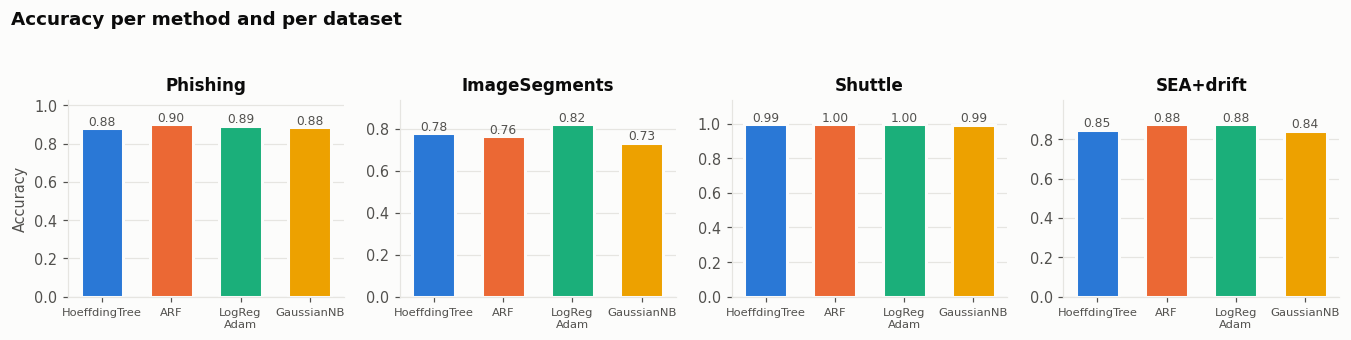

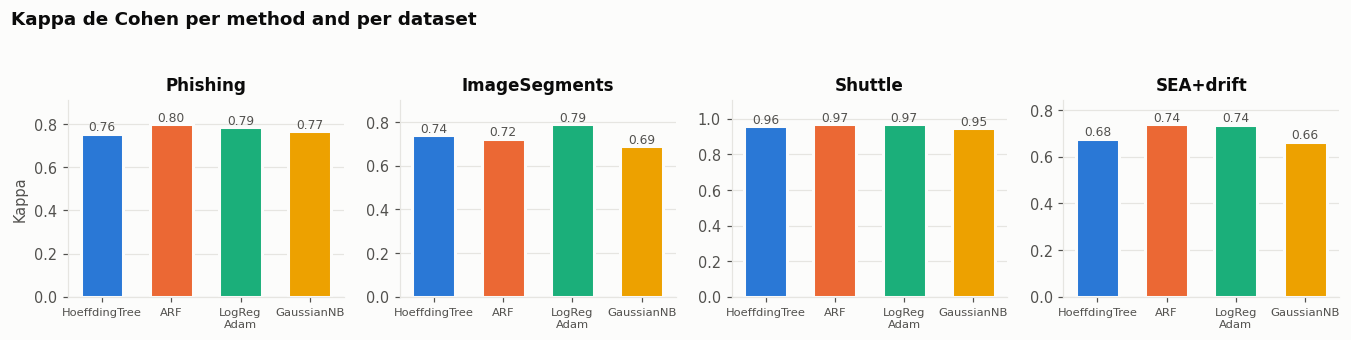

In [34]:
bar_panels(df_clf, "Accuracy", CLF_MODELS, CLF_COLORS, list(CLF_DATASETS), "Accuracy", "Accuracy per method and per dataset ")
bar_panels(df_clf, "Kappa", CLF_MODELS, CLF_COLORS, list(CLF_DATASETS), "Kappa", "Kappa de Cohen per method and per dataset ")

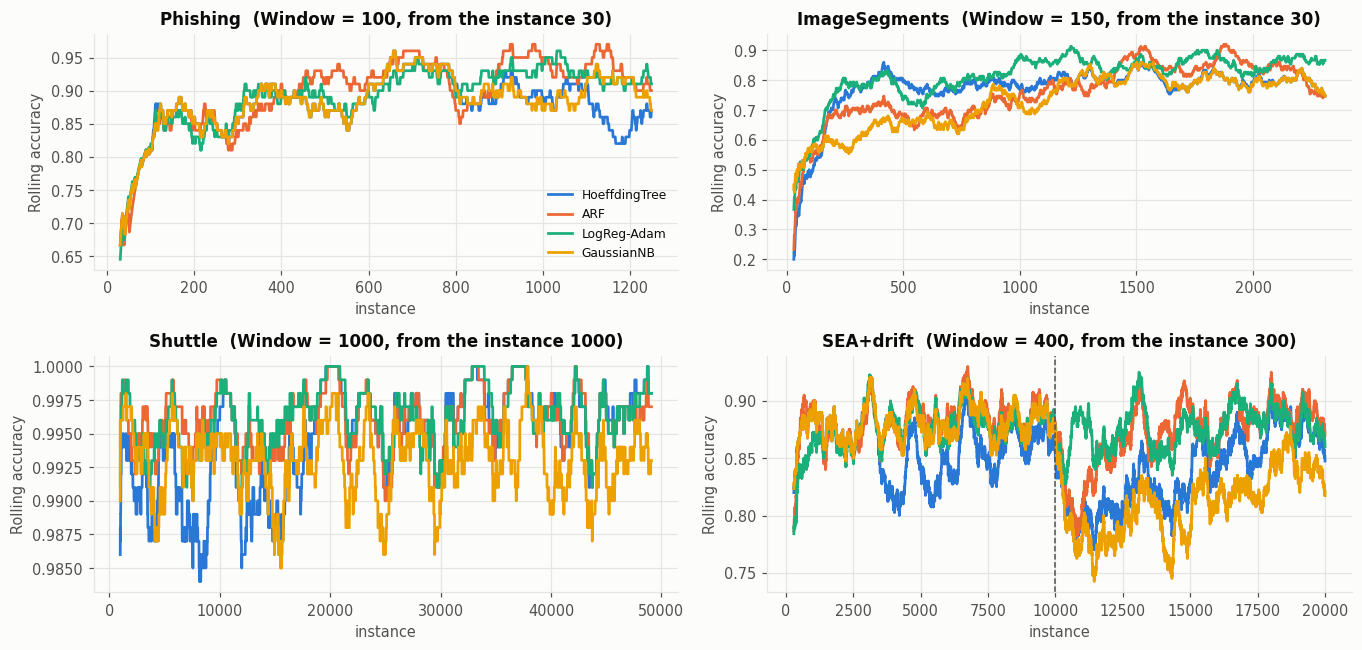

In [35]:
CLF_WINDOWS = {"Phishing": 100, "ImageSegments": 150, "Shuttle": 1000, "SEA+drift": 400}
CLF_STARTS  = {"Phishing": 30, "ImageSegments": 30, "Shuttle": 1000, "SEA+drift": 300}
rolling_panels(clf_errs, list(CLF_DATASETS), CLF_MODELS, CLF_COLORS, CLF_WINDOWS, CLF_STARTS,
               "Rolling accuracy", true_drifts={"SEA+drift": [SEA_DRIFT]}, to_acc=True)

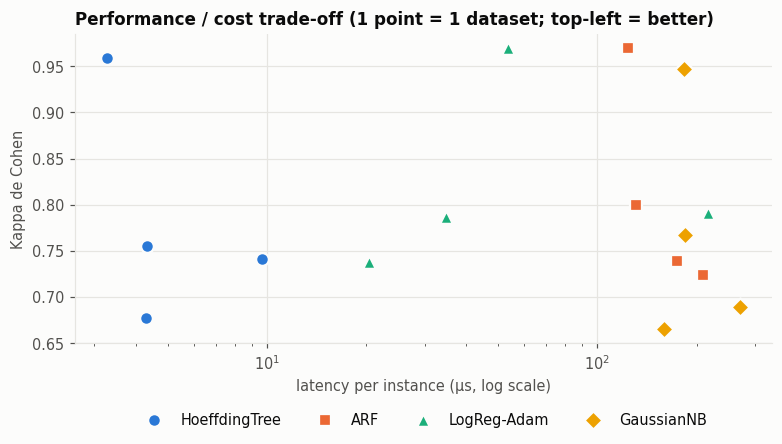

In [36]:
# Performance / cost trade-off in classificatio
markers = dict(zip(CLF_MODELS, ["o", "s", "^", "D"]))
fig, ax = plt.subplots(figsize=(7.2, 4.2))
for m in CLF_MODELS:
    sub = df_clf[df_clf.model == m]
    ax.scatter(sub.latency_us, sub.Kappa, s=70, marker=markers[m], color=CLF_COLORS[m],
               edgecolor=SURFACE, linewidth=1.5, label=m, zorder=3)
ax.set_xscale("log"); ax.set_xlabel("latency per instance (µs, log scale)"); ax.set_ylabel("Kappa de Cohen")
ax.set_title("Performance / cost trade-off (1 point = 1 dataset; top-left = better)", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4); fig.tight_layout(); plt.show()

### 5.4 Step 4 repeated: drift detectors in classification

The monitored signal here is the **binary classification error** (1 = error, 0 = correct prediction) of a `HoeffdingTreeClassifier`. Detectors compared (River default hyperparameters):

| Detector |
|---|
| **ADWIN** |
| **DDM** (*Drift Detection Method*) |
| **EDDM** (*Early DDM*) |
| **HDDM-A** |
| **HDDM-W** |

True drift position of `SEA+drift`: **t = 10,000**; tolerance window for matching an alert: `[10,000, 12,000]`.


In [37]:
DET_CLF = {"ADWIN": lambda: OneSided(drift.ADWIN()),
           "DDM":   lambda: drift.binary.DDM(),
           "EDDM":  lambda: drift.binary.EDDM(),
           "HDDM-A": lambda: drift.binary.HDDMA(),
           "HDDM-W": lambda: drift.binary.HDDMW()}
DET_COLORS_CLF = color_map(list(DET_CLF))
TOL_CLF = 2_000

base_clf = lambda d: make_clf_model("HoeffdingTree", d["binary"])
clf_detect = {ds: detect_only("clf", d["make"], base_clf(d), DET_CLF) for ds, d in CLF_DATASETS.items()}

rows = []
for ds in ["Phishing", "ImageSegments", "Shuttle"]:
    for det, pos in clf_detect[ds].items():
        rows.append(dict(dataset=ds, detector=det, n_alerts=len(pos), positions=pos if len(pos) <= 12 else pos[:12] + ["…"]))
print("Real datasets: alerts (true drifts unknown)")
pd.DataFrame(rows).set_index(["dataset", "detector"])

Real datasets: alerts (true drifts unknown)


n_alerts                                        positions
dataset       detector                                                           
Phishing      ADWIN            0                                               []
              DDM              0                                               []
              EDDM             0                                               []
              HDDM-A           0                                               []
              HDDM-W           0                                               []
ImageSegments ADWIN            0                                               []
              DDM              0                                               []
              EDDM             0                                               []
              HDDM-A           0                                               []
              HDDM-W           0                                               []
Shuttle       ADWIN            0                                               []
              DDM              0                                               []
              EDDM             7  [3466, 6954, 11859, 14784, 24665, 31187, 43119]
              HDDM-A           0                                               []
              HDDM-W           0                                               []

In [38]:
rows = []
for det, pos in clf_detect["SEA+drift"].items():
    delays, fa = score_detection(pos, [SEA_DRIFT], TOL_CLF)
    rows.append({"detector": det, "n_alerts": len(pos), f"drift delay @{SEA_DRIFT}": delays[SEA_DRIFT],
                 "missed drift": delays[SEA_DRIFT] is None, "false alarm": len(fa),
                 "positions": pos if len(pos) <= 12 else pos[:12] + ["…"]})
print("SEA+drift: detection of the known drift")
pd.DataFrame(rows).set_index("detector")

SEA+drift: detection of the known drift


,n_alerts,drift delay @10000,missed drift,false alarm,positions
detector,,,,,
ADWIN,1,784.0,False,0,[10784]
DDM,4,NaN,True,4,"[4033, 4157, 5455, 5580]"
EDDM,27,37.0,False,26,"[4127, 4802, 4992, 5162, 5332, 5511, 5695, 593..."
HDDM-A,1,NaN,True,1,[13722]
HDDM-W,0,NaN,True,0,[]


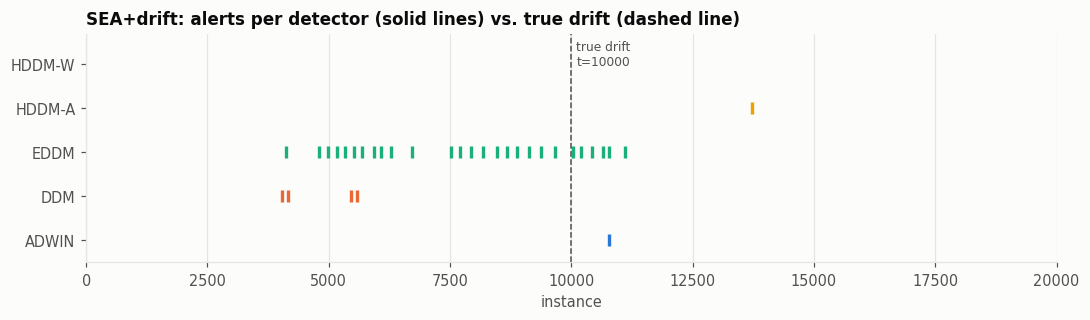

In [39]:
fig, ax = plt.subplots(figsize=(10, 3.0))
for i, (det, pos) in enumerate(clf_detect["SEA+drift"].items()):
    ax.scatter(pos, [i] * len(pos), s=70, marker="|", linewidths=2.2, color=DET_COLORS_CLF[det])
ax.axvline(SEA_DRIFT, color=INK2, ls="--", lw=1)
ax.text(SEA_DRIFT + 100, len(DET_CLF) - 0.45, f"true drift\nt={SEA_DRIFT}", fontsize=8, color=INK2, va="top")
ax.set_yticks(range(len(DET_CLF))); ax.set_yticklabels(list(DET_CLF)); ax.set_ylim(-0.5, len(DET_CLF) - 0.3)
ax.set_xlim(0, N_SEA); ax.set_xlabel("instance"); ax.grid(axis="y", visible=False)
ax.set_title("SEA+drift: alerts per detector (solid lines) vs. true drift (dashed line)", loc="left")
fig.tight_layout(); plt.show()

In [40]:
CLF_VARIANTS = ["HT (no handling)"] + [f"HT + {k}" for k in DET_CLF]
CLF_VAR_COLORS = color_map(CLF_VARIANTS)

def clf_variant(name, d):
    fac = lambda: make_clf_model("HoeffdingTree", d["binary"])
    if name == "HT (no handling)": return fac()
    return ResetOnDrift(fac, DET_CLF[name.replace("HT + ", "")], "clf")

rows, clf_var_errs, clf_resets = [], {}, {}
for ds, d in CLF_DATASETS.items():
    for v in CLF_VARIANTS:
        res, errs, model = prequential(clf_variant(v, d), d["make"](), "clf")
        res.pop("size_kb")
        isreset = isinstance(model, ResetOnDrift)
        clf_resets[(ds, v)] = model.positions if isreset else []
        rows.append(dict(dataset=ds, variante=v, n_resets=len(model.positions) if isreset else np.nan, **res))
        clf_var_errs[(ds, v)] = errs
df_clf_var = pd.DataFrame(rows)
print("Accuracy")
pivot_var(df_clf_var, "Accuracy", CLF_VARIANTS, list(CLF_DATASETS), best="max")

Accuracy


variante,HT (no handling),HT + ADWIN,HT + DDM,HT + EDDM,HT + HDDM-A,HT + HDDM-W
dataset,,,,,,
Phishing,0.880,0.880,0.880,0.880,0.880,0.880
ImageSegments,0.778,0.778,0.778,0.778,0.778,0.778
Shuttle,0.995,0.995,0.995,0.993,0.995,0.995
SEA+drift,0.849,0.857,0.858,0.858,0.848,0.849


In [41]:
print("Kappa ")
pivot_var(df_clf_var, "Kappa", CLF_VARIANTS, list(CLF_DATASETS), best="max")

Kappa 


variante,HT (no handling),HT + ADWIN,HT + DDM,HT + EDDM,HT + HDDM-A,HT + HDDM-W
dataset,,,,,,
Phishing,0.755,0.755,0.755,0.755,0.755,0.755
ImageSegments,0.741,0.741,0.741,0.741,0.741,0.741
Shuttle,0.959,0.959,0.959,0.947,0.959,0.959
SEA+drift,0.678,0.698,0.701,0.700,0.678,0.678


In [42]:
print("Number of triggered rests")
pivot_var(df_clf_var, "n_resets", CLF_VARIANTS[1:-1], list(CLF_DATASETS), "{:.0f}")

Number of triggered rests


variante,HT + ADWIN,HT + DDM,HT + EDDM,HT + HDDM-A
dataset,,,,
Phishing,0,0,0,0
ImageSegments,0,0,0,0
Shuttle,0,0,4,0
SEA+drift,1,2,5,1


In [43]:
# Zoom in on SEA+drift: accuracy before the drift, right after (2,000 instances), and in steady state
def sea_segments(err):
    e = np.asarray(err, float)
    return [1 - np.nanmean(e[:SEA_DRIFT]), 1 - np.nanmean(e[SEA_DRIFT:SEA_DRIFT + TOL_CLF]), 1 - np.nanmean(e[SEA_DRIFT + TOL_CLF:])]
seg = {v: sea_segments(clf_var_errs[("SEA+drift", v)]) for v in CLF_VARIANTS}
print("SEA+drift: accuracy per phase")
pd.DataFrame(seg, index=[f"before drift [0,{SEA_DRIFT})", f"right after [{SEA_DRIFT},{SEA_DRIFT+TOL_CLF})", f"steady state [{SEA_DRIFT+TOL_CLF},{N_SEA})"]).T.style.format("{:.4f}")


SEA+drift: accuracy per phase


,"before drift [0,10000)","right after [10000,12000)","steady state [12000,20000)"
HT (no handling),0.8593,0.8000,0.8480
HT + ADWIN,0.8593,0.8235,0.8616
HT + DDM,0.8586,0.8270,0.8641
HT + EDDM,0.8602,0.8175,0.8659
HT + HDDM-A,0.8593,0.8000,0.8464
HT + HDDM-W,0.8593,0.8000,0.8480


SEA+drift: reset positions (true drift: 10000)
  HT + ADWIN         [10784]
  HT + DDM           [4033, 10715]
  HT + EDDM          [4127, 4247, 11458, 11694, 11844]
  HT + HDDM-A        [13722]


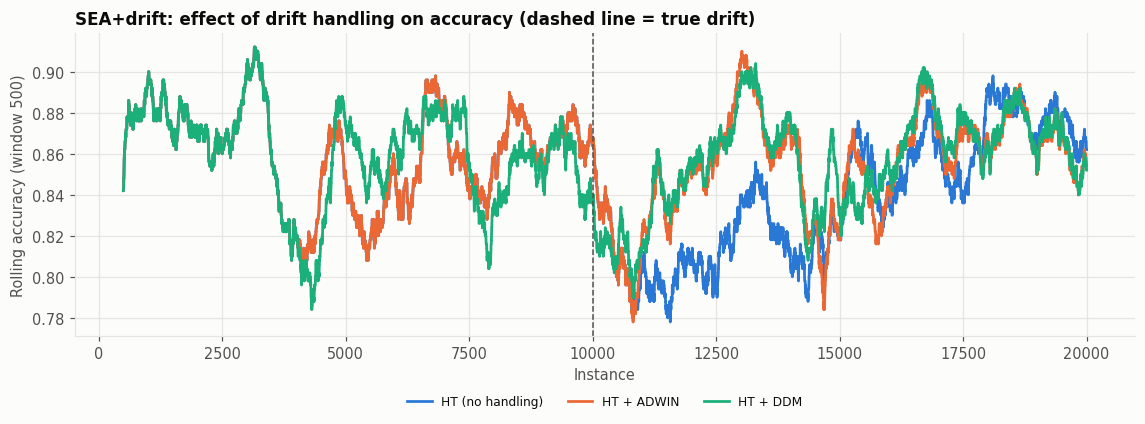

In [44]:
print(f"SEA+drift: reset positions (true drift: {SEA_DRIFT})")
for v in CLF_VARIANTS[1:-1]:
    print(f"  {v:18s}", clf_resets[("SEA+drift", v)])

fig, ax = plt.subplots(figsize=(10.5, 4.0))
for v in ["HT (no handling)", "HT + ADWIN", "HT + DDM"]:       # 3 readable variants
    s = (1 - pd.Series(clf_var_errs[("SEA+drift", v)])).rolling(500, min_periods=1).mean()
    ax.plot(s.index[500:], s.values[500:], color=CLF_VAR_COLORS[v], label=v)
ax.axvline(SEA_DRIFT, color=INK2, ls="--", lw=1)
ax.set_xlabel("Instance"); ax.set_ylabel("Rolling accuracy (window 500)")
ax.set_title("SEA+drift: effect of drift handling on accuracy (dashed line = true drift)", loc="left")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16)); fig.tight_layout(); plt.show()


## Step 6 — Analysis report (Part 1: River)

Times and model sizes vary from one run, one machine and one River version to another: only orders of magnitude should be interpreted.

### 6.1 Protocol and implementation lessons

Everything was evaluated prequentially, with the same seeds, the same streams and the same hyperparameters (River's default values unless stated otherwise). Three protocol choices turned out to be decisive, and each was discovered by reading the first results:

1. **The first prediction of an untrained regressor distorts RMSE and R².** (it equals `|y|`); it is excluded from those two metrics
2. **The preprocessing must be adapted to each model**  In regression, standardising `X` and `y` is essential for the Hoeffding trees (linear leaves), the ARF and the linear model; the KNN needs standardised `X` and one-hot encoding but no scaling of `y`. In classification, only logistic regression needs a `StandardScaler`; trees and Naive Bayes are scale-insensitive.
3.  **Resetting a model on drift needs one-sided alerts and a fresh detector after each reset**, otherwise the new model's learning phase triggers cascades of resets.


### 6.2 Regression: comparison of the methods
| Dataset | Best MAE | Worst MAE | Remark |
|---|---|---|---|
| `TrumpApproval` | ARF **0.329** | KNN 0.502 | tree has the best RMSE and R² (0.456; 0.929) |
| `ChickWeights` | LinReg-Adam **16.5** | KNN 26.4 | R²: 0.866 vs 0.729 |
| `SP500Stocks` | tree **0.574** ≈ ARF 0.575 | KNN 0.619 | **R² ≤ 0 for all models** |
| `FriedmanDrift` | tree **1.98** | KNN 2.63 | ARF only 2.42 |

- **No method wins everywhere.** The ranking depends on the dataset, and the windowed KNN has the highest MAE on all four.
- **`SP500Stocks` is a control case:** the next-day return is almost unpredictable, and no model beats the mean (R² from −0.05 to −0.17); the most flexible model (KNN) strays furthest because it fits noise.
- **`FriedmanDrift`:** the ARF is *worse* than a single tree and its rolling error jumps right after the first drift (≈ 3.9 vs ≈ 3). Plausible cause (not tested): each ARF tree sees only a subset of the features, and only 5 of the 10 are informative.
- **Cost (our machine):** linear model 32–132 µs per instance, tree 181–197 µs, KNN 91–814 µs, **ARF 1.1–4.6 ms (≈ 6–25× the tree)**. Model size: linear 2–5 KB, KNN 17–49 KB, tree 17–512 KB, ARF 170 KB–9.6 MB. The ARF's extra cost pays off against the single tree only on `TrumpApproval` and `ChickWeights`, and on `ChickWeights` the far cheaper linear model is better still.


### 6.3 Regression: drift detection and handling
| Detector (`FriedmanDrift`, drifts at 4,000 and 7,000) | Alerts | Delays | False alarms |
|---|---|---|---|
| ADWIN | 2 | 32 / 40 | 0 |
| Page-Hinkley | 2 | 201 / 224 | 0 |
| KSWIN | 13 | 17 / 19 | 11 |

ADWIN is the best compromise; Page-Hinkley is clean but about six times slower; KSWIN is the fastest but very noisy. On the three real datasets the detectors are almost silent (0 to 1 alert), consistent with rather stationary streams.

**Resetting the tree on alert brings no gain:** `FriedmanDrift` MAE is 1.98 without handling vs 2.03 (ADWIN), 2.05 (Page-Hinkley) and 2.15 (KSWIN). After the first drift the plain tree adapts by itself, while the reset discards a tree trained on 4,000 instances (segment [4,000, 7,000): 2.23 with ADWIN vs 2.05 without).

### 6.4 Classification: comparison of the methods
| Dataset | Best Kappa | Worst Kappa | Remark |
|---|---|---|---|
| `Phishing` | ARF **0.800** | tree 0.755 | accuracy 0.902 vs 0.880 |
| `ImageSegments` (7 classes) | LogReg-Adam **0.791** | GaussianNB 0.689 | ARF (0.724) is below the single tree (0.741) |
| `Shuttle` (93 % majority class) | ARF = LogReg **0.970** | GaussianNB 0.947 | accuracy ≥ 0.993 for all: use Kappa / Macro-F1 |
| `SEA+drift` | ARF **0.740** ≈ LogReg 0.738 | GaussianNB 0.665 | accuracy 0.877 / 0.875 vs 0.844–0.849 |

- **Logistic regression with Adam is surprisingly competitive:** first or within 0.002 Kappa of the best on 3 datasets out of 4, with 1–8 KB of memory. On `SEA` it is natural (the true boundary is linear and the model keeps learning after the drift).
- **Cost (our machine):** tree 3–10 µs, LogReg 20–217 µs, ARF 124–209 µs (**≈ 20–40× the tree**, and 14–100× its memory), GaussianNB 160–271 µs (≈ 30–60× the tree, since it is pure Python). On `Shuttle` and `SEA`, LogReg matches the ARF with **2× (Shuttle) to 9× (SEA) less time** and 40–500× less memory.

### 6.5 Classification: drift detection and handling (`SEA+drift`, drift at 10,000)
| Detector | Alerts | Outcome |
|---|---|---|
| ADWIN | 1 | detected, delay **784**, no false alarm |
| DDM | 4 | missed (alerts at 4,033–5,580) |
| EDDM | 27 | one alert at +37, but 26 false alarms: the "detection" is probably by chance |
| HDDM-A | 1 | missed (alert at 13,722) |
| HDDM-W | 0 | missed |

Only ADWIN gives a clean result, at the price of a long delay (the drift is moderate and buried in 10 % noise). The thresholds were not tuned. On the real datasets all detectors are silent except EDDM on `Shuttle` (7 alerts, probably false: its 4 resets *lower* Kappa from 0.959 to 0.947).

**Here, handling the drift helps:** in the steady state [12,000, 20,000) accuracy rises from 0.848 (no handling) to 0.862 (ADWIN), 0.864 (DDM) and 0.866 (EDDM); Kappa from 0.678 to 0.698–0.701. Unlike in regression, the tree keeps splits that have become wrong (hypothesis, not tested) and a fresh tree relearns quickly on a 3-feature stream.

### 6.6 Conclusions of Part 1
1. **No model is best everywhere**
2. **A cheap adaptive linear model is a strong baseline** (best on `ChickWeights`, best or tied on 3 classification datasets); the ARF must justify its 6–40× latency and 10–100× memory, and often does not.
3. **ADWIN is the most reliable detector** (0 false alarms, delay 32–40 on a marked drift, 784 on a moderate noisy one); Page-Hinkley is slow, KSWIN and EDDM noisy, DDM/HDDM miss a moderate drift with default thresholds.
4. **Reacting to drift is not always worthwhile:** a reset brings nothing when the model adapts by itself (regression) and helps when the learned structure becomes wrong (classification).
5. **Limits:** one seed, default hyperparameters, no known drift in the real datasets, latency measured on a non-dedicated machine.

---
# Part 2: CapyMOA (steps 7 to 10)


**Protocol (identical to Part 1)**: prequential evaluation (test-then-train), fixed seed (`SEED = 42`), same data and hyperparameters aligned between the two libraries,
performance **and** cost (total time, latency per instance).



---
#  Step 7 : Installing CapyMOA



In [47]:
!pip install -q capymoa


In [49]:
import os, subprocess
if "JAVA_HOME" not in os.environ:
    _out = subprocess.run(["java", "-XshowSettings:properties", "-version"], capture_output=True, text=True).stderr
    _home = [l.split("=", 1)[1].strip() for l in _out.splitlines() if l.strip().startswith("java.home")]
    if _home: os.environ["JAVA_HOME"] = _home[0]

In [53]:
import  time, json, math, random, itertools, platform, warnings
from matplotlib.colors import LinearSegmentedColormap

import river,capymoa
from river import datasets, tree, forest, linear_model, naive_bayes, optim, preprocessing, metrics, utils
from river.datasets import synth
from capymoa.stream import NumpyStream
from capymoa.classifier import HoeffdingTree, AdaptiveRandomForestClassifier, SGDClassifier, NaiveBayes

warnings.filterwarnings("ignore")
FIG = "figures_part2"; os.makedirs(FIG, exist_ok=True)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # fixed order
GRAY = "#8a8a86"
LIB_COLORS = {"River": PALETTE[0], "CapyMOA": PALETTE[1]}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

def savefig(name):
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print("CapyMOA", capymoa.__version__, "| River", river.__version__, "| Python", platform.python_version())

CapyMOA 0.15.1 | River 0.27.0 | Python 3.13.18


---
#  Step 8 : Classification: River vs CapyMOA

### 8.1 The 4 methods and their equivalents (aligned hyperparameters)


| Method | River (Part 1) | CapyMOA (closest equivalent) | Alignment |
|---|---|---|---|
| Tree | `HoeffdingTreeClassifier()` | `HoeffdingTree` | `grace_period=200`, confidence `1e-7` (River's defaults), adaptive Naive Bayes leaves, pre-pruning active in both |
| Ensemble | `forest.ARFClassifier(n_models=10)` | `AdaptiveRandomForestClassifier(ensemble_size=10)` | 10 trees, feature subset of size `√d` in both |
| Linear | `StandardScaler() \| LogisticRegression(optim.Adam(lr=0.01))` (one-vs-rest if multiclass) | `SGDClassifier(loss="log_loss", learning_rate="constant", eta0=0.01)` | same (logistic) loss, same step 0.01 and same online-standardised inputs; **the optimiser differs**: CapyMOA relies on scikit-learn, whose `SGDClassifier` has no Adam, so it uses a constant-step SGD |
| Other | `GaussianNB` | `NaiveBayes` | Gaussian naive Bayes in both |

**Datasets**: exactly those of Part 1 (step 5.2), the same instances in the same order: `Phishing`, `ImageSegments`, `Shuttle`, `SEA+drift` .



In [54]:
# --- Part 1 classification datasets, reused as they are (same instances, same order) ---
def encode(d):
    """List of (x, y): y = bool for binary datasets, integer class index for multiclass ones."""
    items = list(d["make"]())
    if d["binary"]: return [(x, bool(y)) for x, y in items]
    idx = {c: i for i, c in enumerate(sorted({y for _, y in items}))}
    return [(x, idx[y]) for x, y in items]

clf_data   = {name: encode(d) for name, d in CLF_DATASETS.items()}          # CLF_DATASETS comes from Part 1 (step 5.2)
clf_binary = {name: d["binary"] for name, d in CLF_DATASETS.items()}
clf_drifts = {"SEA+drift": [SEA_DRIFT]}

# --- Conversion for CapyMOA: NumpyStream, then a list of Java instances (created once, outside the timing) ---
def online_standardize(d):
    """ONLINE standardisation (statistics of past instances), for CapyMOA's linear model."""
    s, out = preprocessing.StandardScaler(), []
    for x, y in d:
        s.learn_one(x); out.append((s.transform_one(x), y))
    return out

def to_capymoa(d, name):
    X = np.array([[x[k] for k in x] for x, _ in d], dtype=float)
    y = np.array([int(v) for _, v in d])
    st = NumpyStream(X, y, dataset_name=name, feature_names=[str(k) for k in d[0][0]], target_name="class", target_type="categorical")
    schema, inst = st.get_schema(), []
    st.restart()
    while st.has_more_instances(): inst.append(st.next_instance())
    return schema, inst

capy = {}
for name, d in clf_data.items():
    schema, inst = to_capymoa(d, name)
    _, inst_std = to_capymoa(online_standardize(d), name + "_std")
    capy[name] = dict(schema=schema, inst=inst, inst_std=inst_std, n_features=len(d[0][0]))
print({k: (len(v["inst"]), v["n_features"]) for k, v in capy.items()})

{'Phishing': (1250, 9), 'ImageSegments': (2310, 18), 'Shuttle': (49097, 9), 'SEA+drift': (20000, 3)}


In [55]:
METHODS = CLF_MODELS      # ["HoeffdingTree", "ARF", "LogReg-Adam", "GaussianNB"] : the Part 1 methods

def river_model(mname, dname):
    return make_clf_model(mname, clf_binary[dname])      # exactly the Part 1 pipelines (incl. its preprocessing)

def capy_methods(schema, d):
    return {
        "HoeffdingTree": lambda: HoeffdingTree(schema, random_seed=SEED, grace_period=200, confidence=1e-7, disable_prepruning=False),
        "ARF":           lambda: AdaptiveRandomForestClassifier(schema, ensemble_size=10, max_features=math.sqrt(d) / d, random_seed=SEED),
        "LogReg-Adam":   lambda: SGDClassifier(schema, loss="log_loss", learning_rate="constant", eta0=0.01, random_seed=SEED),
        "GaussianNB":    lambda: NaiveBayes(schema),
    }

### 8.2 The evaluation loop



In [56]:
def prequential_lib(predict, learn, items, window):
    ms = {"Accuracy": metrics.Accuracy(), "MacroF1": metrics.MacroF1(), "Kappa": metrics.CohenKappa()}   # same metrics as Part 1
    roll = utils.Rolling(metrics.Accuracy, window_size=window)
    lat, curve = np.empty(len(items)), np.empty(len(items))
    for i, (inp, y) in enumerate(items):
        t0 = time.perf_counter()
        y_pred = predict(inp)                 # test
        learn(inp, y)                         # then train
        lat[i] = time.perf_counter() - t0
        y_pred = 0 if y_pred is None else y_pred   # abstention -> class 0 / negative class (like CapyMOA)
        for m in ms.values(): m.update(y, y_pred)
        roll.update(y, y_pred); curve[i] = roll.get()
    out = {k: m.get() for k, m in ms.items()}
    out.update({"Total time (s)": lat.sum(), "Mean latency (ms)": lat.mean() * 1e3, "p95 latency (ms)": np.percentile(lat, 95) * 1e3})
    return out, curve

def run_river(make, d, window):
    m = make(); return prequential_lib(m.predict_one, m.learn_one, d, window)

def run_capymoa(make, inst, ys, window):
    m = make(); return prequential_lib(m.predict, lambda ins, y: m.train(ins), list(zip(inst, ys)), window)

# JIT warm-up (results discarded)
_w = capy["Shuttle"]
for mk in capy_methods(_w["schema"], _w["n_features"]).values():
    m = mk()
    for ins in _w["inst"][:1000]: m.predict(ins); m.train(ins)
print("JVM warmed up.")

JVM warmed up.


In [57]:
rows, curves = [], {}
for dname, d in clf_data.items():
    ys, window, c = [y for _, y in d], max(50, len(d) // 20), capy[dname]
    cm = capy_methods(c["schema"], c["n_features"])
    for mname in METHODS:
        r, cv = run_river(lambda: river_model(mname, dname), d, window)
        rows.append({"Library": "River", "Dataset": dname, "Method": mname, **r}); curves[("River", dname, mname)] = cv
        inst = c["inst_std"] if mname == "LogReg-Adam" else c["inst"]      # the linear model receives standardised inputs
        r, cv = run_capymoa(cm[mname], inst, ys, window)
        rows.append({"Library": "CapyMOA", "Dataset": dname, "Method": mname, **r}); curves[("CapyMOA", dname, mname)] = cv
    print(f"✓ {dname}")
clf_df = pd.DataFrame(rows)
clf_df.to_csv("results_part2_clf_river_vs_capymoa.csv", index=False)

✓ Phishing
✓ ImageSegments
✓ Shuttle
✓ SEA+drift


### 8.3 Results and check against CapyMOA's official evaluator

In [58]:
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
for dname in clf_data:
    print(f"\n=== {dname} ===")
    display(clf_df[clf_df.Dataset == dname].pivot(index="Method", columns="Library",
            values=["Accuracy", "MacroF1", "Kappa", "Total time (s)", "Mean latency (ms)"]).loc[METHODS])


=== Phishing ===


Accuracy       MacroF1         Kappa       Total time (s)       Mean latency (ms)      
Library        CapyMOA River CapyMOA River CapyMOA River        CapyMOA River           CapyMOA River
Method                                                                                               
HoeffdingTree    0.877 0.879   0.875 0.877   0.750 0.754          0.242 0.009             0.194 0.008
ARF              0.900 0.901   0.899 0.899   0.797 0.799          1.527 0.299             1.222 0.240
LogReg-Adam      0.892 0.894   0.891 0.893   0.782 0.787          2.072 0.072             1.657 0.057
GaussianNB       0.884 0.884   0.883 0.883   0.765 0.766          0.054 0.217             0.044 0.174


=== ImageSegments ===


Accuracy       MacroF1         Kappa       Total time (s)       Mean latency (ms)      
Library        CapyMOA River CapyMOA River CapyMOA River        CapyMOA River           CapyMOA River
Method                                                                                               
HoeffdingTree    0.778 0.778   0.768 0.766   0.741 0.741          0.227 0.027             0.098 0.012
ARF              0.681 0.763   0.682 0.759   0.628 0.723          1.530 0.531             0.662 0.230
LogReg-Adam      0.796 0.820   0.773 0.804   0.762 0.790         13.483 0.475             5.837 0.206
GaussianNB       0.779 0.733   0.769 0.732   0.742 0.689          0.061 0.622             0.027 0.269


=== Shuttle ===


Accuracy       MacroF1         Kappa       Total time (s)       Mean latency (ms)      
Library        CapyMOA River CapyMOA River CapyMOA River        CapyMOA River           CapyMOA River
Method                                                                                               
HoeffdingTree    0.997 0.995   0.988 0.979   0.976 0.959          4.707 0.148             0.096 0.003
ARF              0.999 0.996   0.997 0.985   0.993 0.969          5.460 5.782             0.111 0.118
LogReg-Adam      0.996 0.996   0.985 0.985   0.971 0.970         76.021 1.853             1.548 0.038
GaussianNB       0.992 0.993   0.971 0.974   0.942 0.947          1.039 8.772             0.021 0.179


=== SEA+drift ===


Accuracy       MacroF1         Kappa       Total time (s)       Mean latency (ms)      
Library        CapyMOA River CapyMOA River CapyMOA River        CapyMOA River           CapyMOA River
Method                                                                                               
HoeffdingTree    0.849 0.849   0.838 0.838   0.678 0.678          1.273 0.083             0.064 0.004
ARF              0.878 0.877   0.871 0.870   0.742 0.740          4.714 3.019             0.236 0.151
LogReg-Adam      0.882 0.875   0.877 0.869   0.753 0.738         31.470 0.395             1.574 0.020
GaussianNB       0.844 0.844   0.831 0.831   0.665 0.665          0.431 3.441             0.022 0.172

In [60]:
# Check: our loop vs CapyMOA's official evaluator (Shuttle, HoeffdingTree)
from capymoa.evaluation import prequential_evaluation
c = capy["Shuttle"]; ys = [y for _, y in clf_data["Shuttle"]]
mk = capy_methods(c["schema"], c["n_features"])["HoeffdingTree"]

m = mk(); r, _ = run_capymoa(lambda: m, c["inst"], ys, 500)                      # our loop (abstention -> negative class)
st = NumpyStream(np.array([[x[k] for k in x] for x, _ in clf_data["Shuttle"]]), np.array([int(y) for y in ys]),
                 feature_names=[str(k) for k in clf_data["Shuttle"][0][0]], target_name="class", target_type="categorical")
official = prequential_evaluation(stream=st, learner=mk(), window_size=500)
print(f"Accuracy  our loop: {100 * r['Accuracy']:.2f} %   |   official CapyMOA evaluator: {official.cumulative.accuracy():.2f} %")

Accuracy  our loop: 99.69 %   |   official CapyMOA evaluator: 99.69 %


**Figure 17  Predictive quality, River vs CapyMOA** (rows: Accuracy, Macro-F1, Kappa; columns: datasets; two bars per method).

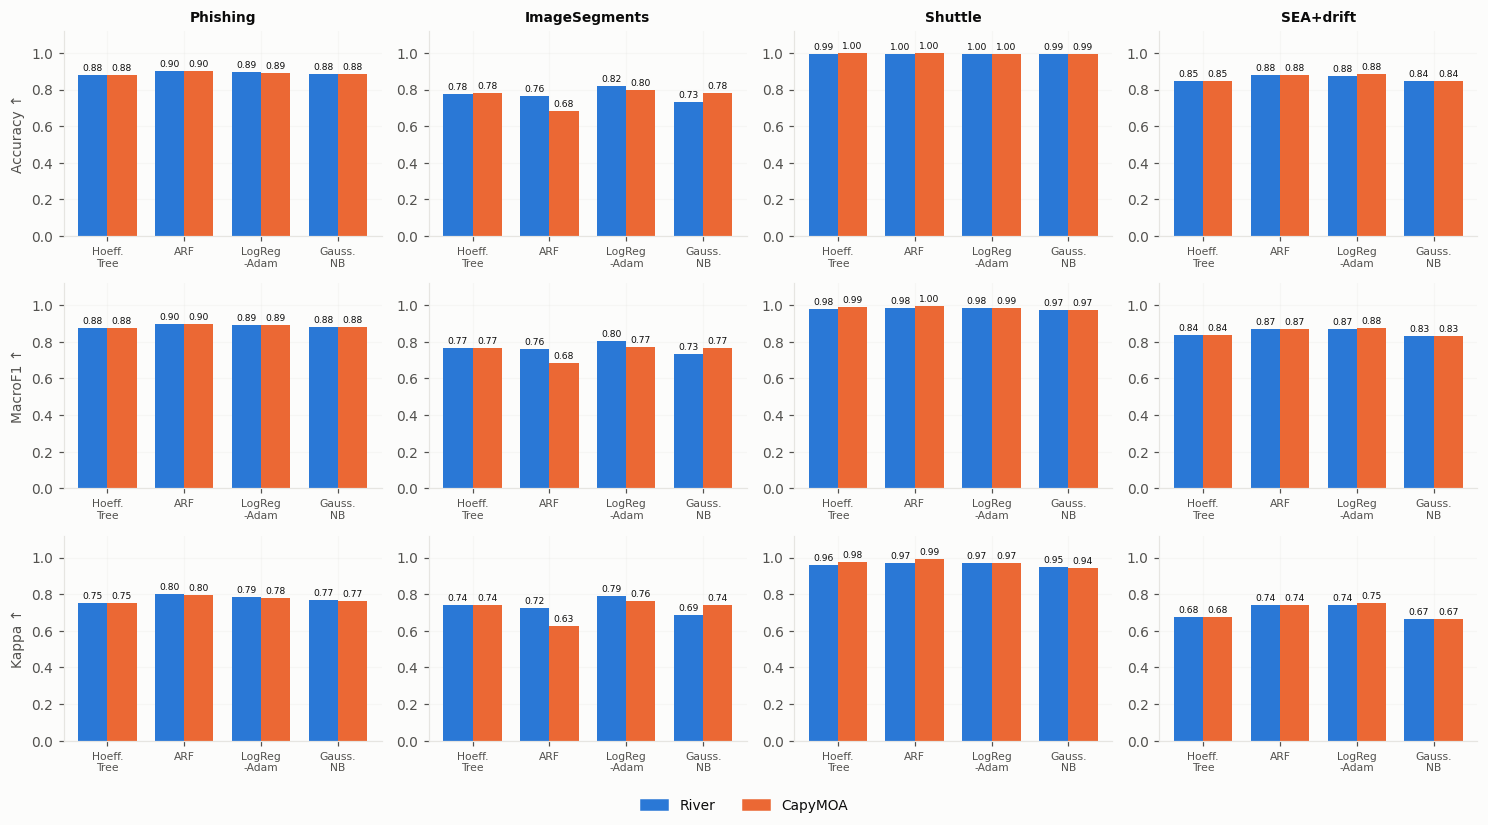

In [61]:
def plot_lib_bars(df, metric_names, fname):
    ds = df.Dataset.unique(); fig, axes = plt.subplots(len(metric_names), len(ds), figsize=(3.4 * len(ds), 2.5 * len(metric_names)))
    x = np.arange(len(METHODS)); w = .38
    for i, met in enumerate(metric_names):
        for j, d in enumerate(ds):
            ax = axes[i, j]
            for k, lib in enumerate(["River", "CapyMOA"]):
                v = [df[(df.Dataset == d) & (df["Method"] == m) & (df["Library"] == lib)][met].iloc[0] for m in METHODS]
                b = ax.bar(x + (k - .5) * w, v, w, color=LIB_COLORS[lib], label=lib)
                ax.bar_label(b, fmt="%.2f", fontsize=6, padding=1.5)
            ax.set_xticks(x); ax.set_xticklabels([m.replace("Hoeffding", "Hoeff.\n").replace("Adaptive", "Adapt.\n").replace("Gaussian", "Gauss.\n").replace("LogReg", "LogReg\n") for m in METHODS], fontsize=7)
            ax.set_ylim(0, 1.12)
            if i == 0: ax.set_title(d, fontsize=9)
            if j == 0: ax.set_ylabel(met + " ↑")
    fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in LIB_COLORS.values()], labels=list(LIB_COLORS), loc="lower center", ncol=2, frameon=False)
    plt.tight_layout(rect=(0, .04, 1, 1)); savefig(fname)

plot_lib_bars(clf_df, ["Accuracy", "MacroF1", "Kappa"], "fig17_river_vs_capymoa_quality")

**Figure 18  Cost: total time and mean latency per instance** (logarithmic scale).

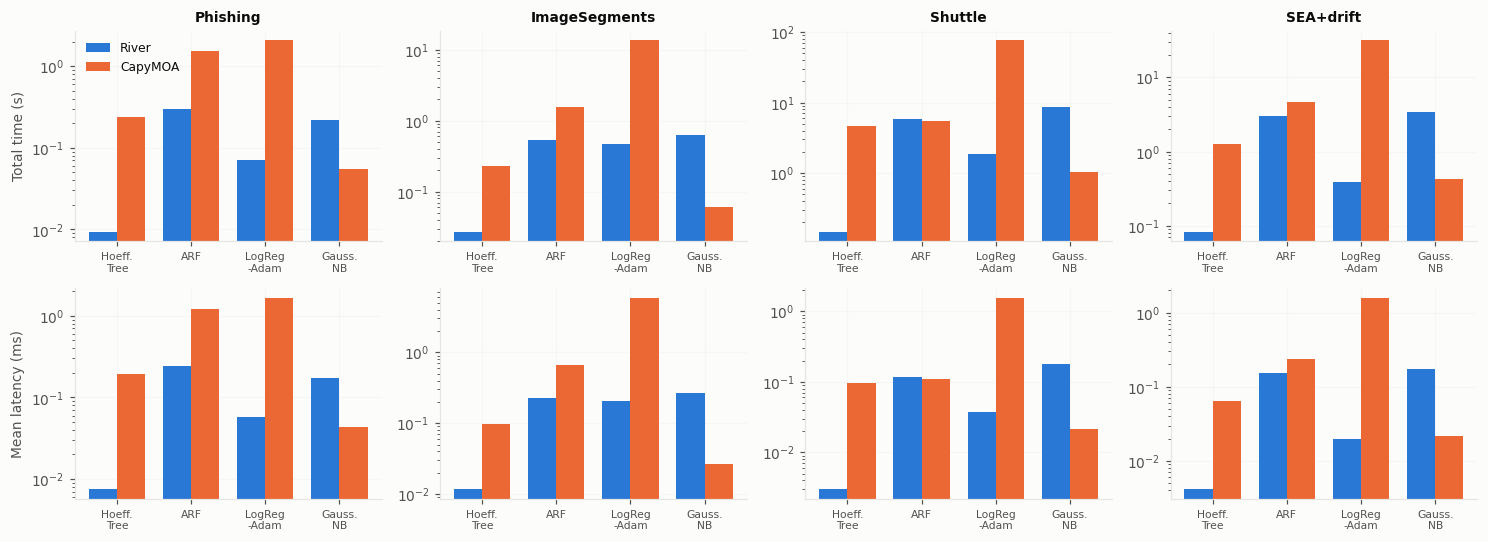

In [62]:
def plot_lib_cost(df, fname):
    ds = df.Dataset.unique(); cols = ["Total time (s)", "Mean latency (ms)"]
    fig, axes = plt.subplots(2, len(ds), figsize=(3.4 * len(ds), 5)); x = np.arange(len(METHODS)); w = .38
    for i, col in enumerate(cols):
        for j, d in enumerate(ds):
            ax = axes[i, j]
            for k, lib in enumerate(["River", "CapyMOA"]):
                v = [df[(df.Dataset == d) & (df["Method"] == m) & (df["Library"] == lib)][col].iloc[0] for m in METHODS]
                ax.bar(x + (k - .5) * w, v, w, color=LIB_COLORS[lib], label=lib)
            ax.set_yscale("log"); ax.set_xticks(x)
            ax.set_xticklabels([m.replace("Hoeffding", "Hoeff.\n").replace("Adaptive", "Adapt.\n").replace("Gaussian", "Gauss.\n").replace("LogReg", "LogReg\n") for m in METHODS], fontsize=7)
            if i == 0: ax.set_title(d, fontsize=9)
            if j == 0: ax.set_ylabel(col)
    axes[0, 0].legend(frameon=False, fontsize=8)
    plt.tight_layout(); savefig(fname)

plot_lib_cost(clf_df, "fig18_river_vs_capymoa_cost")

**Figure 19  CapyMOA ÷ River latency ratio** (by method and by dataset). Orange = CapyMOA slower, blue = CapyMOA faster; the number is the factor.

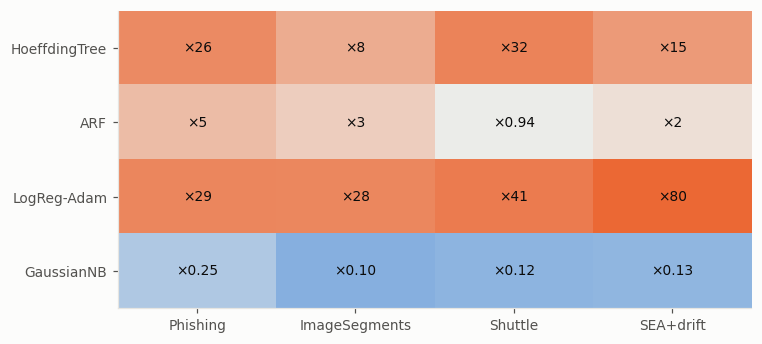

In [63]:
def plot_ratio(df, fname):
    piv = df.pivot_table(index="Method", columns=["Dataset", "Library"], values="Mean latency (ms)").loc[METHODS]
    ds = df.Dataset.unique(); R = np.array([[piv[(d, "CapyMOA")][m] / piv[(d, "River")][m] for d in ds] for m in METHODS])
    cmap = LinearSegmentedColormap.from_list("div", [PALETTE[0], "#eeeeea", PALETTE[1]])
    fig, ax = plt.subplots(figsize=(7, 3.2)); lim = np.log10(np.abs(R).max())
    ax.imshow(np.log10(R), cmap=cmap, vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(len(ds))); ax.set_xticklabels(ds); ax.set_yticks(range(len(METHODS))); ax.set_yticklabels(METHODS)
    for i in range(len(METHODS)):
        for j in range(len(ds)):
            ax.text(j, i, f"×{R[i, j]:.0f}" if R[i, j] >= 1.5 else f"×{R[i, j]:.2f}", ha="center", va="center", fontsize=9, color="#0b0b0b")
    plt.tight_layout(); savefig(fname)
    return pd.DataFrame(R, index=METHODS, columns=ds)

ratio_df = plot_ratio(clf_df, "fig19_latency_ratio")

**Figure 20  Accuracy / latency trade-off.** Each small dot = one dataset; each large dot = the mean over the 4 datasets. Shape = method, colour = library. The **top-left** is ideal.

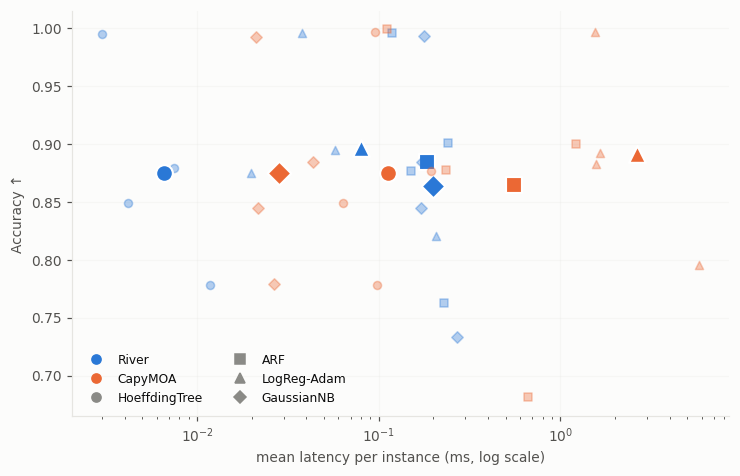

In [64]:
def plot_lib_tradeoff(df, fname):
    markers = dict(zip(METHODS, ["o", "s", "^", "D"])); fig, ax = plt.subplots(figsize=(6.8, 4.4))
    for lib in ["River", "CapyMOA"]:
        for m in METHODS:
            s = df[(df["Library"] == lib) & (df["Method"] == m)]
            ax.scatter(s["Mean latency (ms)"], s["Accuracy"], color=LIB_COLORS[lib], marker=markers[m], alpha=.35, s=28)
            ax.scatter(s["Mean latency (ms)"].mean(), s["Accuracy"].mean(), color=LIB_COLORS[lib], marker=markers[m], s=120, edgecolor="white", lw=1.4)
    ax.set_xscale("log"); ax.set_xlabel("mean latency per instance (ms, log scale)"); ax.set_ylabel("Accuracy ↑")
    h1 = [plt.Line2D([], [], marker="o", ls="", color=c, label=l) for l, c in LIB_COLORS.items()]
    h2 = [plt.Line2D([], [], marker=markers[m], ls="", color=GRAY, label=m) for m in METHODS]
    ax.legend(handles=h1 + h2, frameon=False, fontsize=8, ncol=2); plt.tight_layout(); savefig(fname)

plot_lib_tradeoff(clf_df, "fig20_river_vs_capymoa_tradeoff")

**Figure 21  Rolling accuracy on SEA+drift (abrupt drift at t = 10,000, red line)**

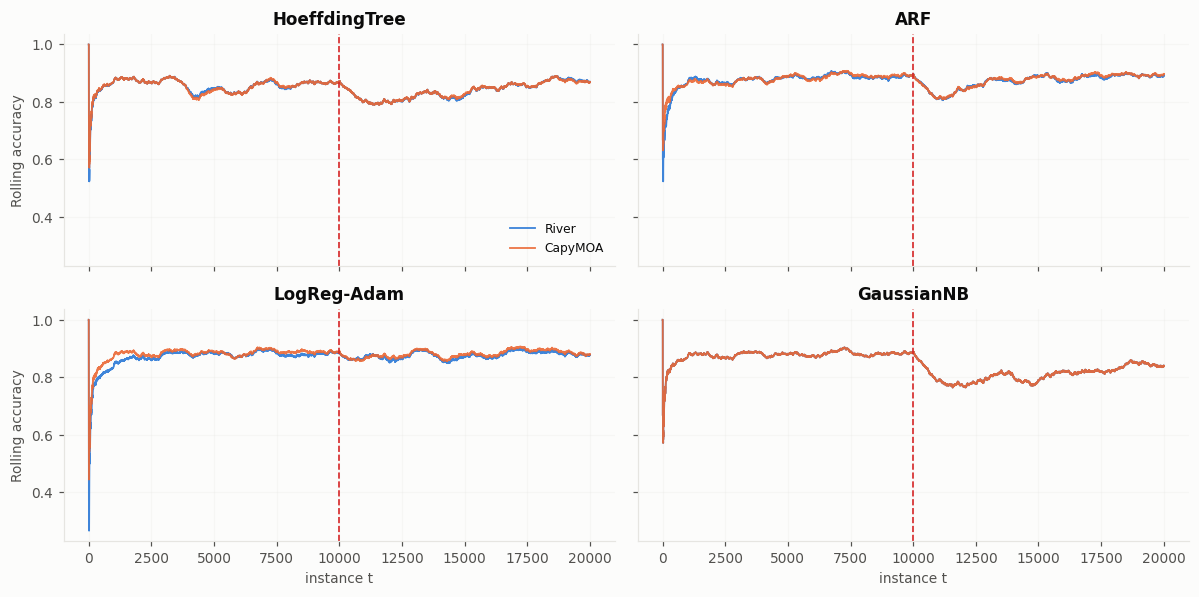

In [65]:
def plot_lib_curves(curves, dname, drifts, fname):
    fig, axes = plt.subplots(2, 2, figsize=(11, 5.5), sharex=True, sharey=True)
    for ax, m in zip(axes.ravel(), METHODS):
        for lib in ["River", "CapyMOA"]:
            ax.plot(curves[(lib, dname, m)], color=LIB_COLORS[lib], lw=1.2, label=lib, alpha=.9)
        for p in drifts: ax.axvline(p, color="#d62728", ls="--", lw=1.1)
        ax.set_title(m)
    for ax in axes[1]: ax.set_xlabel("instance t")
    for ax in axes[:, 0]: ax.set_ylabel("Rolling accuracy")
    axes[0, 0].legend(frameon=False, fontsize=8, loc="lower right"); plt.tight_layout(); savefig(fname)

plot_lib_curves(curves, "SEA+drift", clf_drifts["SEA+drift"], "fig21_river_vs_capymoa_rolling")

In [66]:
# Summary table: means over the 4 datasets
(clf_df.groupby(["Method", "Library"])[["Accuracy", "MacroF1", "Kappa", "Total time (s)", "Mean latency (ms)"]]
       .mean().loc[METHODS])

Accuracy  MacroF1  Kappa  Total time (s)  Mean latency (ms)
Method        Library                                                             
HoeffdingTree CapyMOA     0.875    0.867  0.786           1.612              0.113
              River       0.875    0.865  0.783           0.067              0.007
ARF           CapyMOA     0.865    0.862  0.790           3.308              0.558
              River       0.884    0.878  0.808           2.408              0.185
LogReg-Adam   CapyMOA     0.892    0.881  0.817          30.762              2.654
              River       0.896    0.888  0.821           0.699              0.080
GaussianNB    CapyMOA     0.875    0.863  0.779           0.396              0.028
              River       0.864    0.855  0.767           3.263              0.198

In [67]:
# Automatic summary used in the discussion below (accuracy gap and latency ratio, CapyMOA vs River)
acc = clf_df.pivot_table(index=["Dataset", "Method"], columns="Library", values="Accuracy")
gap = (acc["CapyMOA"] - acc["River"]) * 100
print("Accuracy gap CapyMOA − River, in points:")
display(gap.unstack("Dataset").loc[METHODS].round(2))
print(f"mean |gap| = {gap.abs().mean():.2f} points   |   max |gap| = {gap.abs().max():.2f} points   (over {len(gap)} comparisons)")
print("\nLatency ratio CapyMOA / River (> 1: CapyMOA slower):")
display(ratio_df.round(1))

Accuracy gap CapyMOA − River, in points:


Dataset,ImageSegments,Phishing,SEA+drift,Shuttle
Method,,,,
HoeffdingTree,0.040,-0.240,-0.000,0.230
ARF,-8.140,-0.080,0.100,0.300
LogReg-Adam,-2.470,-0.240,0.730,0.010
GaussianNB,4.550,0.000,0.000,-0.070


mean |gap| = 1.08 points   |   max |gap| = 8.14 points   (over 16 comparisons)

Latency ratio CapyMOA / River (> 1: CapyMOA slower):


,Phishing,ImageSegments,Shuttle,SEA+drift
HoeffdingTree,25.800,8.300,31.900,15.300
ARF,5.100,2.900,0.900,1.600
LogReg-Adam,28.900,28.400,41.000,79.800
GaussianNB,0.300,0.100,0.100,0.100


### 8.4 Reading the results (River vs CapyMOA)

**Quality.** With the same data, metrics and hyperparameters, the two libraries agree closely: the check against CapyMOA's official evaluator matches exactly (Shuttle, 99.69 % both ways). Over the 16 comparisons the mean accuracy gap is **1.08 points**, and **every gap is ≤ 0.73 points except on `ImageSegments`** (max 8.14). Three cases differ:
- **`ARF` on `ImageSegments`: CapyMOA is 8.1 points lower** (0.681 vs 0.763; Kappa 0.628 vs 0.723). Both ARF implementations differ in details (feature-subset drawing, tree replacement), and this is the smallest, multiclass dataset (2,310 instances, 7 classes), where an ensemble of 10 trees is most sensitive; the cause was not isolated.
- **`GaussianNB` on `ImageSegments`: CapyMOA is 4.6 points higher** (0.779 vs 0.733), probably an implementation difference in the Gaussian estimator (not tested).
- **`LogReg-Adam`:** −2.5 points on `ImageSegments` and +0.7 on `SEA+drift`; the optimisers differ (Adam in River, constant-step SGD through scikit-learn in CapyMOA) and so does the multiclass scheme.

**Cost: this is where the libraries differ** (CapyMOA ÷ River latency, figure 19):

| Method | Ratio | Reading |
|---|---|---|
| `HoeffdingTree` | ×8 to ×32 | River: 0.003–0.012 ms per instance; the Python↔Java call dominates a very light model |
| `ARF` | ×0.9 to ×5 | the gap closes as the per-instance computation grows (×0.94 on `Shuttle`) |
| `LogReg-Adam` | **×28 to ×80** | 1.5–5.8 ms per instance in CapyMOA: scikit-learn's `partial_fit` is called at every instance |
| `GaussianNB` | **×0.10 to ×0.25** | CapyMOA is **4 to 10 times faster** than River's pure-Python implementation |

Interpretation (consistent with the measurements, without fine-grained profiling): every CapyMOA call crosses the Python↔Java boundary at a fixed cost, which dominates light models; when the per-instance computation is heavier (Naive Bayes, ensembles), compiled Java regains the advantage. Memory is not compared (`tracemalloc` does not see the JVM).

**Drift (figure 21).** On `SEA+drift`, the River and CapyMOA curves overlap for every method: same drop at t = 10,000, same recovery.

**Conclusion.** For an equivalent algorithm, **accuracy does not separate the libraries** (except on one small multiclass dataset); the choice is made on **cost per instance** and **ecosystem** .

---
#  Step 9  clustering

### 9.1 Methods and datasets


| Method | Online | Offline |
|---|---|---|
| **CluStream (built-in k-means)** `Clustream_with_kmeans` | micro-clusters over a sliding horizon | built-in k-means |
| **CluStream + weighted k-means** `Clustream` | same | k-means weighted by micro-cluster size (scikit-learn, **our addition**) |
| **ClusTree + weighted k-means** `ClusTree` | micro-clusters stored in a tree (very fast) | same |
| **DenStream** `Denstream_with_dbscan` (ε = 0.02, **default**) | density micro-clusters | DBSCAN |
| **DenStream** (ε = 0.1·√d, **adapted to the dimension**) | same | same |

The data are rescaled to [0, 1]ᵈ (the scale for which the default `epsilon=0.02` was designed). The **labels are never used for learning**: they are used only to *measure* quality.

**4 unsupervised streams**:
* **Blobs-static**: 5 well-separated Gaussians in 2D, stationary (10,000 points);
* **Blobs-drift**: the same 5 Gaussians **moving**; at t = 5000 a **6th cluster appears**, at t = 7500 **cluster 0 disappears**: typical stream evolution;
* **Bananas** (River, 2D, 5,300 points): two **non-convex** shapes that overlap slightly;
* **ImageSegments** (River, 18 dimensions, 2,310 points): 7 types of image regions, a real higher-dimensional case.

### 9.2 Quality measures
Every 500 instances, we take a snapshot of the macro-clusters, assign each point of the **last 500 instances** to its nearest centre, then measure:
* **ARI** (Adjusted Rand Index) and **NMI**: agreement with the true classes (external; 1 = perfect, 0 = chance);
* **Silhouette**: cohesion/separation without using the labels (internal; −1 to 1);
* **SSQ**: mean squared distance to the nearest centre (lower = more compact, but depends on the number of clusters);
* **k**: number of macro-clusters found; and **throughput** (instances/second) for the cost.

As a **reference (ceiling)**, we add an *offline k-means* that sees the whole window and knows the true number of clusters: no stream algorithm should do better.

In [68]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
import capymoa.cluster as K

rng = np.random.default_rng(SEED)
C0 = np.array([[.2, .2], [.8, .2], [.5, .5], [.2, .8], [.8, .8]])          # 5 starting centres
V  = np.array([[.15, .1], [-.15, .1], [0, .1], [.1, -.1], [-.1, -.1]])       # total displacement of each centre
NEW = np.array([.5, .88])                                                    # 6th cluster (appears at t=5000)

def blobs(n=10_000, drift=False, std=.04):
    X, y = np.empty((n, 2)), np.empty(n, dtype=int)
    for t in range(n):
        active = [0, 1, 2, 3, 4]
        if drift:
            if t >= 5000: active.append(5)
            if t >= 7500: active.remove(0)
        c = rng.choice(active)
        ctr = NEW if c == 5 else C0[c] + (V[c] * t / n if drift else 0)
        X[t], y[t] = ctr + rng.normal(0, std, 2), c
    return X, y

def river_unsup(ds):
    s, X, y = preprocessing.MinMaxScaler(), [], []          # ONLINE [0,1] rescaling
    for x, t in ds:
        s.learn_one(x); xs = s.transform_one(x); X.append([xs[k] for k in x]); y.append(t)
    return np.array(X), np.unique(np.array(y), return_inverse=True)[1]

clu_data = {   # name -> (X, true_y, known_k)
    "Blobs-static":  (*blobs(), 5),
    "Blobs-drift":   (*blobs(drift=True), 5),
    "Bananas":       (*river_unsup(datasets.Bananas()), 2),
    "ImageSegments": (*river_unsup(datasets.ImageSegments()), 7),
}
pd.DataFrame({n: {"N": len(X), "Dimensions": X.shape[1], "True classes": len(np.unique(y)), "k given to k-means": k}
              for n, (X, y, k) in clu_data.items()}).T

,N,Dimensions,True classes,k given to k-means
Blobs-static,10000,2,5,5
Blobs-drift,10000,2,6,5
Bananas,5300,2,2,2
ImageSegments,2310,18,7,7


In [69]:
STEP = 500   # snapshot every 500 instances; evaluation window = last 500 instances

def clu_methods(schema, k, d):
    eps = 0.1 * math.sqrt(d)
    return {
        "CluStream (built-in k-means)": (lambda: K.Clustream_with_kmeans(schema, time_window=1000, max_num_kernels=100, k_option=k), "macro"),
        "CluStream + weighted k-means": (lambda: K.Clustream(schema, time_window=1000, max_num_kernels=100), "micro_km"),
        "ClusTree + weighted k-means":  (lambda: K.ClusTree(schema, horizon=1000), "micro_km"),
        "DenStream (ε=0.02 default)":   (lambda: K.Denstream_with_dbscan(schema, horizon=1000, epsilon=0.02, mu=1, init_points=1000), "macro"),
        "DenStream (ε=0.1·√d)":        (lambda: K.Denstream_with_dbscan(schema, horizon=1000, epsilon=eps, mu=1, init_points=1000), "macro"),
    }
CLU_NAMES = list(clu_methods(None, 2, 2))
CLU_COLORS = dict(zip(CLU_NAMES, PALETTE))

def centers_of(c, kind, k):
    if kind == "micro_km":       # micro-clusters -> k-means weighted by their weight
        m = c.get_micro_clustering_result(); C, w = np.array(m.get_centers()), np.array(m.get_weights())
        return C if len(C) < k else KMeans(k, n_init=5, random_state=0).fit(C, sample_weight=np.maximum(w, 1e-9)).cluster_centers_
    return np.array(c.get_clustering_result().get_centers())

def quality(C, W, yw):
    if len(C) == 0: return dict(ARI=np.nan, NMI=np.nan, Silhouette=np.nan, SSQ=np.nan, k=0)
    d2 = ((W[:, None, :] - C[None]) ** 2).sum(-1); lab = d2.argmin(1)
    return dict(ARI=adjusted_rand_score(yw, lab), NMI=normalized_mutual_info_score(yw, lab),
                Silhouette=silhouette_score(W, lab) if len(set(lab)) > 1 else np.nan, SSQ=d2.min(1).mean(), k=len(C))

snap, centers_log, speed = [], {}, {}
for dname, (X, y, k) in clu_data.items():
    st = NumpyStream(X, y, dataset_name=dname, target_type="categorical"); schema = st.get_schema()
    # offline reference (ceiling): k-means on the window, k = number of true classes in the window
    for t in range(STEP, len(X) + 1, STEP):
        W, yw = X[t - STEP:t], y[t - STEP:t]
        C = KMeans(len(np.unique(yw)), n_init=5, random_state=0).fit(W).cluster_centers_
        snap.append({"Dataset": dname, "Method": "Offline reference", "t": t, **quality(C, W, yw)})
    for mname, (mk, kind) in clu_methods(schema, k, X.shape[1]).items():
        st.restart(); c = mk(); train_time = 0.0
        for i in range(len(X)):
            ins = st.next_instance(); t0 = time.perf_counter(); c.train(ins); train_time += time.perf_counter() - t0
            if (i + 1) % STEP == 0:
                C = centers_of(c, kind, k); centers_log[(dname, mname, i + 1)] = C
                snap.append({"Dataset": dname, "Method": mname, "t": i + 1, **quality(C, X[i + 1 - STEP:i + 1], y[i + 1 - STEP:i + 1])})
        speed[(dname, mname)] = len(X) / train_time
    print(f"✓ {dname}")
snap = pd.DataFrame(snap); snap.to_csv("results_part2_clustering_snapshots.csv", index=False)

✓ Blobs-static
✓ Blobs-drift
✓ Bananas
✓ ImageSegments


### 9.3 Mean quality (snapshots from t = 1000, after DenStream's initialisation)

In [70]:
late = snap[snap.t >= 1000]
summary = (late.groupby(["Dataset", "Method"])[["ARI", "NMI", "Silhouette", "SSQ", "k"]].mean()
              .join(pd.Series(speed, name="Throughput (inst/s)").rename_axis(["Dataset", "Method"])))
summary.to_csv("results_part2_clustering_summary.csv")
for dname in clu_data:
    print(f"\n=== {dname} ===")
    display(summary.loc[dname].loc[["Offline reference"] + CLU_NAMES].round(3))


=== Blobs-static ===


,ARI,NMI,Silhouette,SSQ,k,Throughput (inst/s)
Method,,,,,,
Offline reference,1.000,1.000,0.828,0.003,5.000,NaN
CluStream (built-in k-means),0.821,0.910,0.637,0.022,5.000,"2,211.415"
CluStream + weighted k-means,1.000,1.000,0.828,0.003,5.000,"1,957.449"
ClusTree + weighted k-means,1.000,1.000,0.828,0.003,5.000,"13,675.957"
DenStream (ε=0.02 default),0.874,0.917,0.574,0.003,9.474,"4,202.632"
DenStream (ε=0.1·√d),1.000,1.000,0.828,0.003,5.000,"6,205.272"



=== Blobs-drift ===


,ARI,NMI,Silhouette,SSQ,k,Throughput (inst/s)
Method,,,,,,
Offline reference,0.998,0.998,0.769,0.003,5.263,NaN
CluStream (built-in k-means),0.735,0.861,0.552,0.015,5.000,"1,679.157"
CluStream + weighted k-means,0.948,0.973,0.738,0.005,5.000,"1,958.842"
ClusTree + weighted k-means,0.953,0.978,0.742,0.005,5.000,"24,510.828"
DenStream (ε=0.02 default),0.783,0.862,0.396,0.003,12.421,"4,518.669"
DenStream (ε=0.1·√d),0.997,0.996,0.769,0.004,5.526,"5,044.181"



=== Bananas ===


,ARI,NMI,Silhouette,SSQ,k,Throughput (inst/s)
Method,,,,,,
Offline reference,0.026,0.022,0.412,0.039,2.000,NaN
CluStream (built-in k-means),0.023,0.019,0.378,0.066,2.000,"2,524.406"
CluStream + weighted k-means,0.024,0.019,0.409,0.040,2.000,"1,927.345"
ClusTree + weighted k-means,0.025,0.021,0.410,0.039,2.000,"18,487.147"
DenStream (ε=0.02 default),0.029,0.190,0.231,0.003,63.667,"4,311.592"
DenStream (ε=0.1·√d),0.007,0.007,0.392,0.067,2.000,"2,883.228"



=== ImageSegments ===


,ARI,NMI,Silhouette,SSQ,k,Throughput (inst/s)
Method,,,,,,
Offline reference,0.529,0.640,0.331,0.174,7.000,NaN
CluStream (built-in k-means),0.486,0.625,0.266,0.300,7.000,640.980
CluStream + weighted k-means,0.541,0.652,0.331,0.186,7.000,870.642
ClusTree + weighted k-means,0.509,0.625,0.324,0.176,7.000,"23,282.988"
DenStream (ε=0.02 default),0.000,0.000,NaN,1.594,1.000,"5,729.618"
DenStream (ε=0.1·√d),0.696,0.750,0.301,0.194,7.667,"4,150.770"


**Figure 22 — Mean quality by method and by dataset**: ARI (agreement with the true classes), silhouette (no labels) and throughput (log scale). The black line is the offline reference.

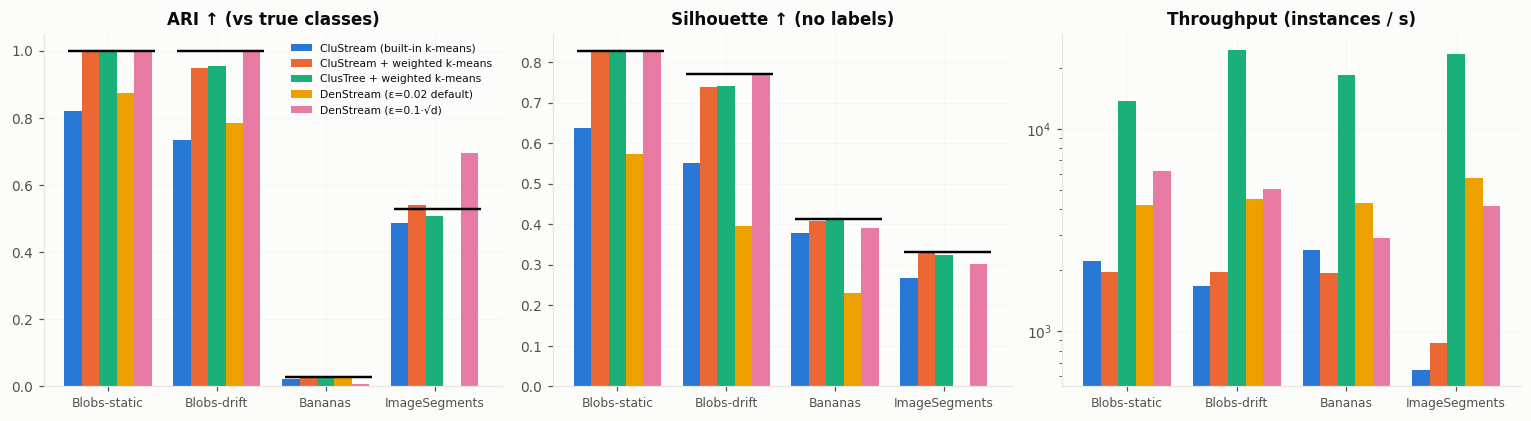

In [71]:
def plot_clu_summary(summary, fname):
    ds = list(clu_data); fig, axes = plt.subplots(1, 3, figsize=(14, 3.9)); w = .8 / len(CLU_NAMES)
    for ax, (col, ttl) in zip(axes, [("ARI", "ARI ↑ (vs true classes)"), ("Silhouette", "Silhouette ↑ (no labels)"), ("Throughput (inst/s)", "Throughput (instances / s)")]):
        for k_, m in enumerate(CLU_NAMES):
            v = [summary.loc[(d, m), col] for d in ds]
            ax.bar(np.arange(len(ds)) + k_ * w, v, w, color=CLU_COLORS[m], label=m)
        if col != "Throughput (inst/s)":
            for j, d in enumerate(ds):
                ax.hlines(summary.loc[(d, "Offline reference"), col], j - .05, j + .8 - .05 + .0, color="k", lw=1.6)
        ax.set_xticks(np.arange(len(ds)) + w * (len(CLU_NAMES) - 1) / 2); ax.set_xticklabels(ds, fontsize=8); ax.set_title(ttl)
        if col == "Throughput (inst/s)": ax.set_yscale("log")
    axes[0].legend(frameon=False, fontsize=7, loc="upper right"); plt.tight_layout(); savefig(fname)

plot_clu_summary(summary, "fig22_clustering_summary")

### 9.4 Evolution of the clusters over the stream (Blobs-drift)

**Figure 23  Quality over time.** Vertical lines: appearance of the 6th cluster (t = 5000) and disappearance of cluster 0 (t = 7500). The dotted curve in the last panel is the true number of clusters.

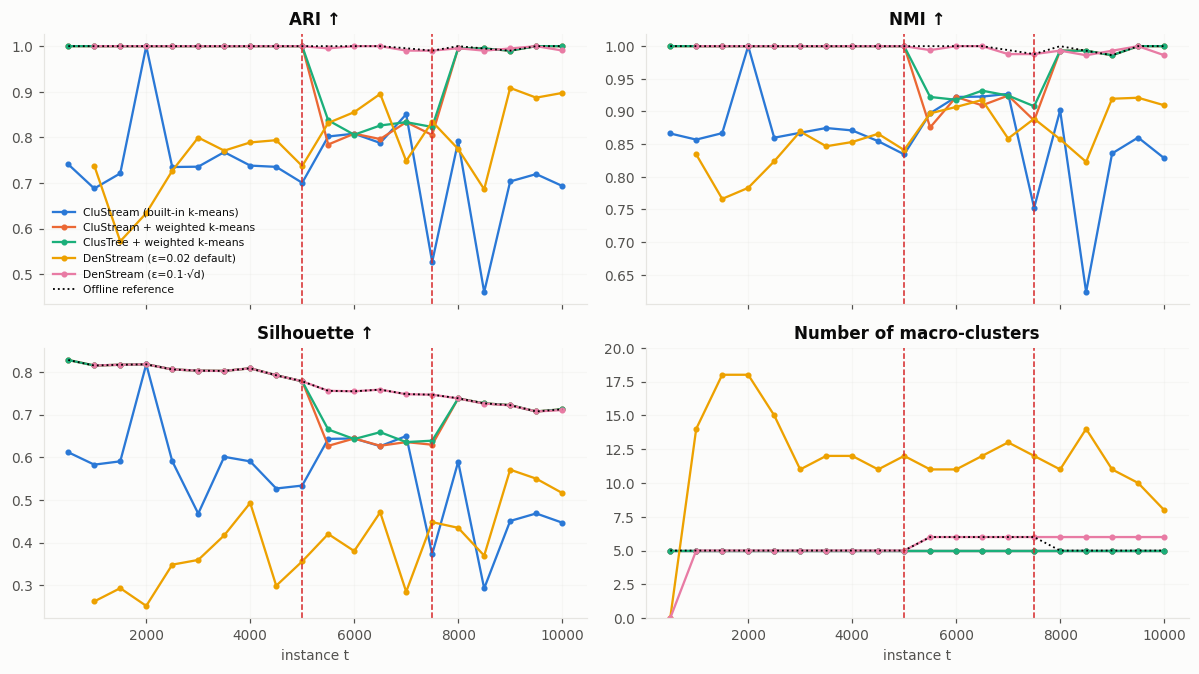

In [72]:
def plot_clu_evolution(dname, fname):
    s = snap[snap.Dataset == dname]; fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
    for ax, (col, ttl) in zip(axes.ravel(), [("ARI", "ARI ↑"), ("NMI", "NMI ↑"), ("Silhouette", "Silhouette ↑"), ("k", "Number of macro-clusters")]):
        for m in CLU_NAMES:
            q = s[s["Method"] == m]; ax.plot(q.t, q[col], color=CLU_COLORS[m], lw=1.5, marker="o", ms=3, label=m)
        r = s[s["Method"] == "Offline reference"]
        if col != "k": ax.plot(r.t, r[col], color="k", lw=1.2, ls=":", label="Offline reference")
        else: ax.plot(r.t, r.k, color="k", lw=1.2, ls=":", label="true k")
        for p in (5000, 7500): ax.axvline(p, color="#d62728", ls="--", lw=1)
        ax.set_title(ttl)
    for ax in axes[1]: ax.set_xlabel("instance t")
    axes[1, 1].set_ylim(0, 20); axes[0, 0].legend(frameon=False, fontsize=7, loc="lower left"); plt.tight_layout(); savefig(fname)

plot_clu_evolution("Blobs-drift", "fig23_clustering_evolution")

**Figure 24  The clusters seen from the inside.** For each method (row) and three moments (columns: t = 2500 before the events, t = 5500 just after the appearance of the 6th cluster, t = 9000 after the disappearance of cluster 0),
the points of the last 500 instances (colour = true class) and the macro-cluster centres (black crosses).

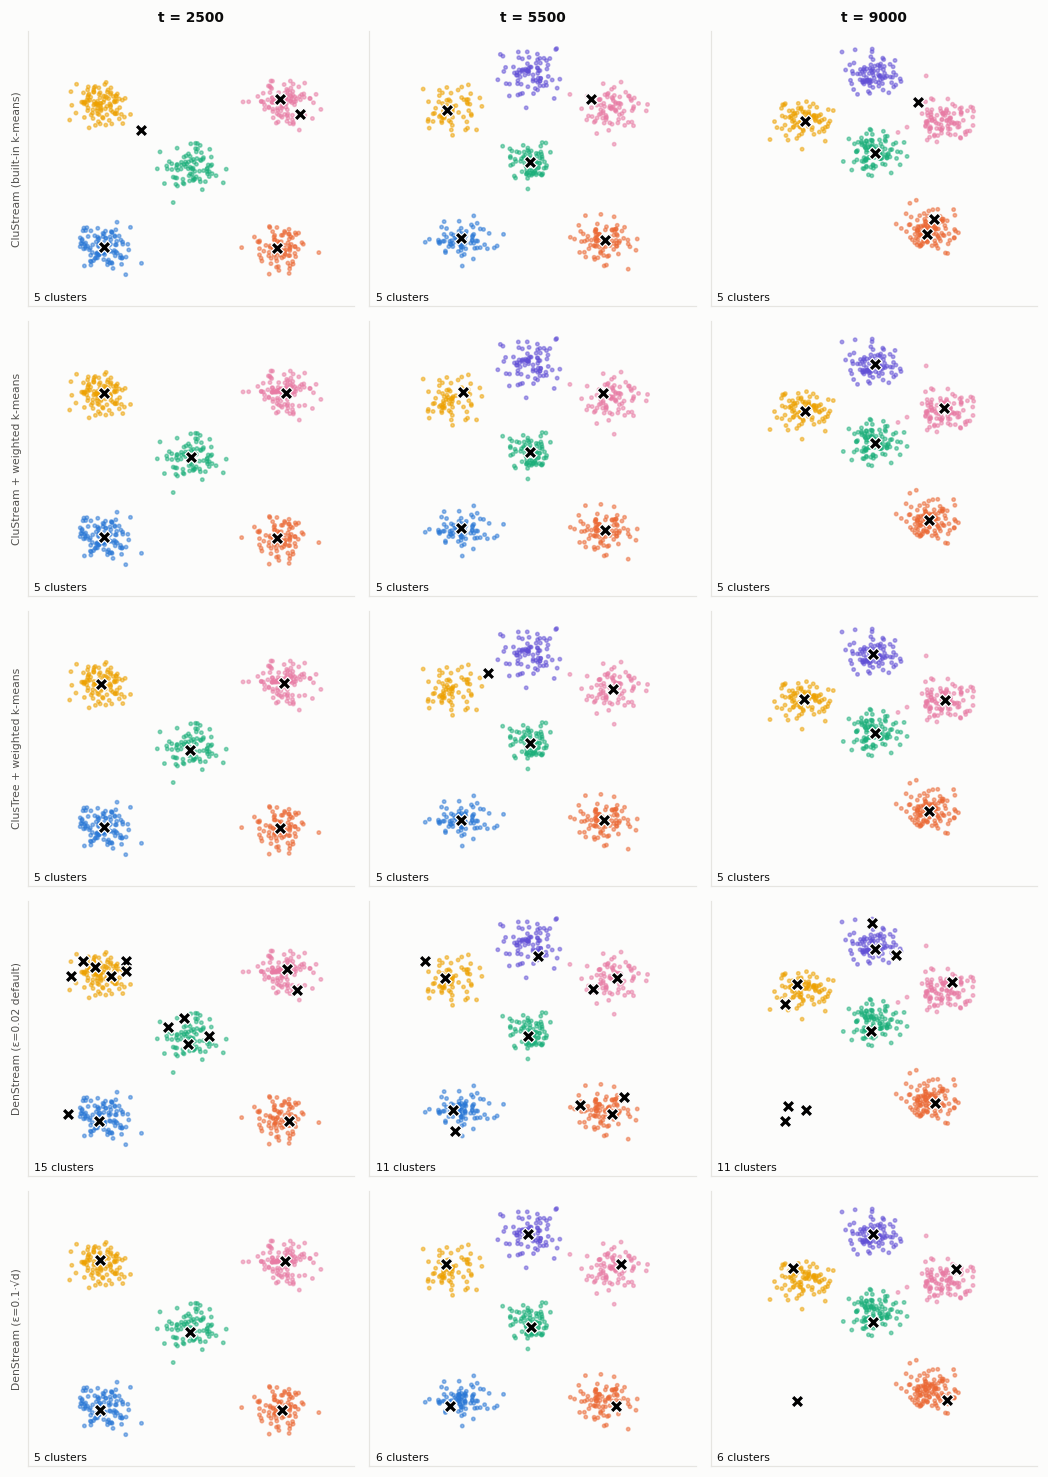

In [73]:
def plot_clu_scatter(dname, times, fname):
    X, y, k = clu_data[dname]; fig, axes = plt.subplots(len(CLU_NAMES), len(times), figsize=(3.2 * len(times), 2.7 * len(CLU_NAMES)), sharex=True, sharey=True)
    for i, m in enumerate(CLU_NAMES):
        for j, t in enumerate(times):
            ax = axes[i, j]; W, yw = X[t - STEP:t], y[t - STEP:t]
            ax.scatter(W[:, 0], W[:, 1], c=[PALETTE[v % 6] for v in yw], s=5, alpha=.5)
            C = centers_log[(dname, m, t)]
            if len(C): ax.scatter(C[:, 0], C[:, 1], marker="X", s=70, color="k", edgecolor="white", lw=.8, zorder=3)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.05); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if i == 0: ax.set_title(f"t = {t}", fontsize=9)
            if j == 0: ax.set_ylabel(m, fontsize=7)
            ax.text(.02, .02, f"{len(C)} clusters", transform=ax.transAxes, fontsize=7)
    plt.tight_layout(); savefig(fname)

plot_clu_scatter("Blobs-drift", [2500, 5500, 9000], "fig24_clustering_scatter")

**Figure 25  Why Bananas is difficult**: on the left the true classes, in the middle the centres of `ClusTree + k-means` (k=2), on the right those of `DenStream` (adapted ε). Centres (hence convex cells) cannot fit two crescent shapes.

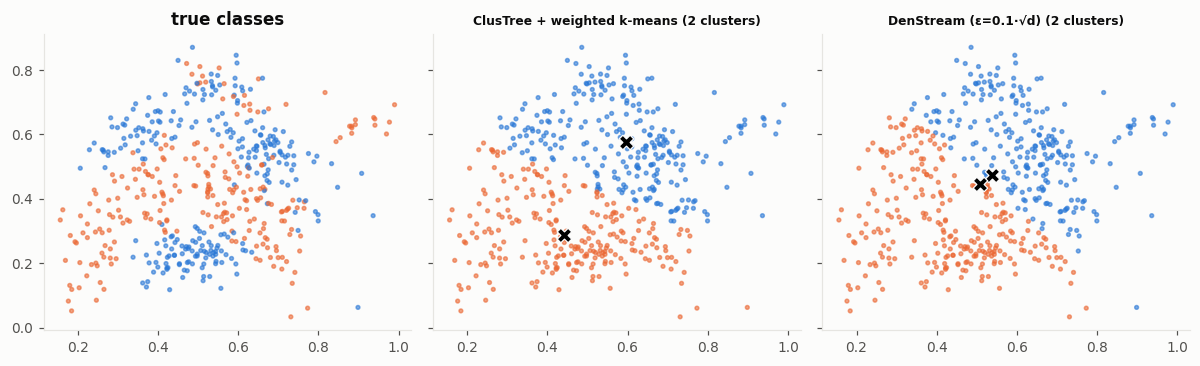

In [74]:
X, y, k = clu_data["Bananas"]; t = 5000; W, yw = X[t - STEP:t], y[t - STEP:t]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
axes[0].scatter(W[:, 0], W[:, 1], c=[PALETTE[v] for v in yw], s=6, alpha=.6); axes[0].set_title("true classes")
for ax, m in zip(axes[1:], ["ClusTree + weighted k-means", "DenStream (ε=0.1·√d)"]):
    C = centers_log[("Bananas", m, t)]
    d2 = ((W[:, None] - C[None]) ** 2).sum(-1); lab = d2.argmin(1)
    ax.scatter(W[:, 0], W[:, 1], c=[PALETTE[v % 6] for v in lab], s=6, alpha=.6)
    ax.scatter(C[:, 0], C[:, 1], marker="X", s=90, color="k", edgecolor="white", lw=.8); ax.set_title(f"{m} ({len(C)} clusters)", fontsize=8)
for ax in axes: ax.grid(False)
plt.tight_layout(); savefig("fig25_bananas_clusters")

### 9.5 Reading the results (clustering)

**Mean quality (figure 22, tables 9.3).**
- **The offline step matters as much as the online step.** With the same CluStream micro-clusters, replacing the built-in k-means by a k-means weighted by micro-cluster size raises ARI from 0.82 to **1.00** (`Blobs-static`) and from 0.74 to **0.95** (`Blobs-drift`). ClusTree + weighted k-means reaches 1.00 and 0.95.
- **DenStream depends strongly on `epsilon`.** The default (0.02) over-segments (9.5 and 12.4 clusters for 5 true ones, 64 on `Bananas`) and collapses to a single cluster in dimension 18 (ARI 0). With ε = 0.1·√d (a rule that uses only the dimension, not the labels) it finds the right k by itself and reaches ARI 1.00 / 0.997.
- **`ImageSegments` (real, 18 D):** tuned DenStream obtains **ARI 0.70, better than the offline k-means reference (0.53)**, because the classes are not spherical.
- **`Bananas`: no method exceeds ARI ≈ 0.03**, reference included: the shapes are non-convex and overlapping, which centroid-based methods cannot capture. Silhouette is still decent (≈ 0.41), so an internal measure alone is misleading: examine both.

**Evolution (figure 23, `Blobs-drift`).** Moving centres are tracked well by ClusTree, weighted CluStream and tuned DenStream. When a 6th cluster appears (t = 5,000), k-means with k = 5 cannot represent it and ARI drops to ≈ 0.8, whereas tuned DenStream finds 6 clusters from t = 5,500 without being told. After cluster 0 disappears (t = 7,500), the k-means methods are correct again, while DenStream keeps a "ghost" centre (k = 6 instead of 5): forgetting is gradual. CluStream with built-in k-means is unstable (ARI oscillating between 0.46 and 1.0).

**Throughput (our machine).** ClusTree processes about 1.4–2.5·10⁴ instances/s, i.e. **2–6× DenStream** (≈ 3–6·10³/s) and **6–36× CluStream** (0.6–2.5·10³/s, slowest in dimension 18).

**Which method?** Known k and compact clusters: **ClusTree + weighted k-means** (reference quality, fastest). Unknown k, appearing/disappearing clusters, non-spherical shapes: **DenStream with a tuned `epsilon`** (never the default as is).



---
#  Step 10 : AutoML in CapyMOA



| Approach |
|---|
| **`BanditClassifier`** (ε-greedy) |
| **`SuccessiveHalvingClassifier`** |
| **`AutoClass`** (Bahri & Georgantas, 2023) |



**Comparison**: we compare against three reference points: the **default `HoeffdingTree`** (no AutoML), the **ARF** forest (10 trees, labelled `AdaptiveRF` in the tables) and the **best / median / worst model of the pool**, computed *a posteriori* by training each configuration separately (a bound that an ideal AutoML would approach).
To limit computation time (Successive Halving trains 15 models in parallel), we use the **first instances** of each dataset: the whole of `Phishing` (1,250) and `ImageSegments` (2,310), the first 5,000 of `Shuttle` and the first 15,000 of `SEA+drift` (so that the drift at t = 10,000 stays inside).

In [75]:
# number of instances used per dataset (Successive Halving trains 15 models at once: too slow on the whole Shuttle stream)
AUTO_N = {"Phishing": 1250, "ImageSegments": 2310, "Shuttle": 5000, "SEA+drift": 15000}   # SEA+drift: the drift (t = 10,000) stays inside
pool_cfg = {"algorithms": [
    {"algorithm": "HoeffdingTree",         "parameters": [{"parameter": "grace_period", "type": "integer", "value": 200, "range": [50, 400]}]},
    {"algorithm": "HoeffdingAdaptiveTree", "parameters": [{"parameter": "grace_period", "type": "integer", "value": 200, "range": [50, 400]}]},
    {"algorithm": "KNN", "parameters": [{"parameter": "k", "type": "integer", "value": 5, "range": [3, 15]},
                                        {"parameter": "window_size", "type": "integer", "value": 300}]}]}
auto_cfg = {"algorithms": [   # same space, with MOA option names (g = grace period, k = neighbours, w = window)
    {"algorithm": "moa.classifiers.trees.HoeffdingTree",         "parameters": [{"parameter": "g", "type": "integer", "value": 200, "range": [50, 400]}]},
    {"algorithm": "moa.classifiers.trees.HoeffdingAdaptiveTree", "parameters": [{"parameter": "g", "type": "integer", "value": 200, "range": [50, 400]}]},
    {"algorithm": "moa.classifiers.lazy.kNN", "parameters": [{"parameter": "k", "type": "integer", "value": 5, "range": [3, 15]},
                                                             {"parameter": "w", "type": "integer", "value": 300, "range": [200, 400]}]}]}
json.dump(pool_cfg, open("automl_pool.json", "w")); json.dump(auto_cfg, open("automl_autoclass.json", "w"))

from capymoa.automl import BanditClassifier, SuccessiveHalvingClassifier, AutoClass, EpsilonGreedy

def describe_model(m):
    p = m.get_params() if hasattr(m, "get_params") else {}
    name = type(m).__name__
    if "grace_period" in p: return f"{name}(grace={p['grace_period']})"
    if "k" in p: return f"kNN(k={p['k']})"
    return name

def automl_approaches(schema, n):
    return {
        "Bandit (ε-greedy)":   lambda: BanditClassifier(schema, random_seed=SEED, config_file="automl_pool.json", policy=EpsilonGreedy(0.1, 100)),
        "Successive Halving":  lambda: SuccessiveHalvingClassifier(schema, random_seed=SEED, config_file="automl_pool.json", max_instances=n, eta=2.0),
        "AutoClass":           lambda: AutoClass(schema, random_seed=SEED, configuration_json="automl_autoclass.json",
                                                 base_classifiers=["trees.HoeffdingTree", "trees.HoeffdingAdaptiveTree", "lazy.kNN"]),
    }

In [76]:
auto_rows, auto_curves, selections, pool_scores = [], {}, {}, {}
for dname, d in clf_data.items():
    d = d[:AUTO_N[dname]]; ys = [y for _, y in d]; c = capy[dname]; n = len(d); window = max(50, n // 20)
    inst, schema = c["inst"][:n], c["schema"]
    def run(make, name):
        m = make(); r, cv = prequential_lib(m.predict, lambda ins, y: m.train(ins), list(zip(inst, ys)), window)
        auto_rows.append({"Dataset": dname, "Approach": name, **r}); auto_curves[(dname, name)] = cv; return m
    # reference points
    run(lambda: HoeffdingTree(schema, random_seed=SEED), "HoeffdingTree (default)")
    run(capy_methods(schema, c["n_features"])["ARF"], "AdaptiveRF (10 trees)")
    # the whole pool, trained separately (a posteriori)
    pool = BanditClassifier(schema, random_seed=SEED, config_file="automl_pool.json").active_models
    sc_ = []
    for m in pool:
        r, cv = prequential_lib(m.predict, lambda ins, y, m=m: m.train(ins), list(zip(inst, ys)), window); sc_.append((describe_model(m), r, cv))
    best = max(sc_, key=lambda s: s[1]["Accuracy"]); med = sorted(sc_, key=lambda s: s[1]["Accuracy"])[len(sc_) // 2]; worst = min(sc_, key=lambda s: s[1]["Accuracy"])
    for lab, s in [("Pool: best (a posteriori)", best), ("Pool: median", med), ("Pool: worst", worst)]:
        auto_rows.append({"Dataset": dname, "Approach": lab, **s[1]}); auto_curves[(dname, lab)] = s[2]
    pool_scores[dname] = {"best": best[0], "worst": worst[0]}
    # the 3 AutoML approaches
    for name, make in automl_approaches(schema, n).items():
        random.seed(SEED); m = run(make, name)
        if name.startswith("Bandit"):
            cnt = m.policy.get_arm_stats()["counts"]; selections[(dname, name)] = describe_model(m.active_models[int(np.argmax(cnt))])
        elif name.startswith("Successive"):
            selections[(dname, name)] = describe_model(m.best_model)
    print(f"✓ {dname}")
auto_df = pd.DataFrame(auto_rows); auto_df.to_csv("results_part2_automl.csv", index=False)

✓ Phishing
✓ ImageSegments
✓ Shuttle
✓ SEA+drift


### 10.1 Results

In [77]:
APPROACHES = ["HoeffdingTree (default)", "AdaptiveRF (10 trees)", "Pool: worst", "Pool: median", "Pool: best (a posteriori)",
              "Bandit (ε-greedy)", "Successive Halving", "AutoClass"]
for dname in clf_data:
    print(f"\n=== {dname} (first {AUTO_N[dname]} instances) ===")
    display(auto_df[auto_df.Dataset == dname].set_index("Approach").loc[APPROACHES, ["Accuracy", "MacroF1", "Kappa", "Total time (s)", "Mean latency (ms)"]])
print("\nModel chosen by the selectors:")
pd.Series(selections).unstack()


=== Phishing (first 1250 instances) ===


,Accuracy,MacroF1,Kappa,Total time (s),Mean latency (ms)
Approach,,,,,
HoeffdingTree (default),0.882,0.880,0.761,0.038,0.031
AdaptiveRF (10 trees),0.900,0.899,0.797,0.706,0.564
Pool: worst,0.851,0.848,0.697,0.209,0.167
Pool: median,0.875,0.874,0.748,0.041,0.033
Pool: best (a posteriori),0.883,0.881,0.762,0.288,0.231
Bandit (ε-greedy),0.878,0.876,0.751,9.680,7.744
Successive Halving,0.871,0.869,0.739,51.949,41.559
AutoClass,0.870,0.868,0.736,0.960,0.768



=== ImageSegments (first 2310 instances) ===


,Accuracy,MacroF1,Kappa,Total time (s),Mean latency (ms)
Approach,,,,,
HoeffdingTree (default),0.778,0.768,0.741,0.075,0.032
AdaptiveRF (10 trees),0.681,0.682,0.628,1.105,0.478
Pool: worst,0.778,0.768,0.741,0.087,0.038
Pool: median,0.783,0.773,0.746,0.413,0.179
Pool: best (a posteriori),0.881,0.880,0.862,0.234,0.101
Bandit (ε-greedy),0.780,0.770,0.743,30.248,13.094
Successive Halving,0.879,0.877,0.859,171.944,74.435
AutoClass,0.872,0.869,0.851,1.677,0.726



=== Shuttle (first 5000 instances) ===


,Accuracy,MacroF1,Kappa,Total time (s),Mean latency (ms)
Approach,,,,,
HoeffdingTree (default),0.993,0.974,0.949,0.486,0.097
AdaptiveRF (10 trees),0.997,0.990,0.981,0.528,0.106
Pool: worst,0.982,0.933,0.867,0.434,0.087
Pool: median,0.992,0.973,0.946,0.156,0.031
Pool: best (a posteriori),0.994,0.980,0.961,0.587,0.117
Bandit (ε-greedy),0.992,0.973,0.946,37.231,7.446
Successive Halving,0.994,0.980,0.959,208.069,41.614
AutoClass,0.993,0.974,0.948,3.479,0.696



=== SEA+drift (first 15000 instances) ===


,Accuracy,MacroF1,Kappa,Total time (s),Mean latency (ms)
Approach,,,,,
HoeffdingTree (default),0.849,0.835,0.672,0.508,0.034
AdaptiveRF (10 trees),0.874,0.863,0.727,4.799,0.320
Pool: worst,0.829,0.818,0.636,1.298,0.087
Pool: median,0.850,0.838,0.677,1.230,0.082
Pool: best (a posteriori),0.855,0.843,0.687,0.802,0.053
Bandit (ε-greedy),0.853,0.841,0.683,131.623,8.775
Successive Halving,0.854,0.841,0.683,688.084,45.872
AutoClass,0.858,0.848,0.696,6.838,0.456



Model chosen by the selectors:


,Bandit (ε-greedy),Successive Halving
ImageSegments,HoeffdingTree(grace=50),kNN(k=3)
Phishing,kNN(k=3),kNN(k=3)
SEA+drift,HoeffdingTree(grace=50),HoeffdingAdaptiveTree(grace=50)
Shuttle,HoeffdingTree(grace=50),kNN(k=3)


**Figure 26 Quality of the AutoML approaches** (Accuracy and Kappa) and **Figure 27  their cost** (total time, log). Grey = reference points; the "Pool: best" bar is the a posteriori bound.

In [ ]:
AUTO_COLORS = {"HoeffdingTree (default)": GRAY, "AdaptiveRF (10 trees)": "#b7b7b2", "Pool: worst": "#d9d9d4", "Pool: median": "#c3c3be",
               "Pool: best (a posteriori)": "#4a4a47", "Bandit (ε-greedy)": PALETTE[0], "Successive Halving": PALETTE[1], "AutoClass": PALETTE[2]}

def plot_auto(df, cols, fname, log=False):
    ds = list(clf_data); fig, axes = plt.subplots(len(cols), len(ds), figsize=(3.4 * len(ds), 2.7 * len(cols) + .8), squeeze=False)
    for i, col in enumerate(cols):
        for j, d in enumerate(ds):
            ax = axes[i, j]; s = df[df.Dataset == d].set_index("Approach").loc[APPROACHES]
            b = ax.bar(range(len(s)), s[col], color=[AUTO_COLORS[a] for a in s.index]); ax.set_xticks([])
            ax.bar_label(b, fmt="%.2f" if not log else "%.3g", fontsize=6, padding=1.5)
            if log: ax.set_yscale("log")
            if i == 0: ax.set_title(d, fontsize=9)
            if j == 0: ax.set_ylabel(col + (" ↑" if col in ("Accuracy", "Kappa") else ""))
            if col in ("Accuracy", "Kappa"): ax.set_ylim(max(0, s[col].min() - .15), min(1.0, s[col].max() + .08))
    fig.legend([plt.Rectangle((0, 0), 1, 1, color=AUTO_COLORS[a]) for a in APPROACHES], APPROACHES, loc="lower center", ncol=4, frameon=False, fontsize=8)
    plt.tight_layout(rect=(0, .1, 1, 1)); savefig(fname)

plot_auto(auto_df, ["Accuracy", "Kappa"], "fig26_automl_quality")
plot_auto(auto_df, ["Total time (s)"], "fig27_automl_cost", log=True)

**Figure 28  Rolling accuracy on SEA+drift (drift at t = 10,000)**: how each approach recovers from the drift.

In [80]:
AUTO_COLORS = {"HoeffdingTree (default)": GRAY, "AdaptiveRF (10 trees)": "#b7b7b2", "Pool: worst": "#d9d9d4", "Pool: median": "#c3c3be",
               "Pool: best (a posteriori)": "#4a4a47", "Bandit (ε-greedy)": PALETTE[0], "Successive Halving": PALETTE[1], "AutoClass": PALETTE[2]}

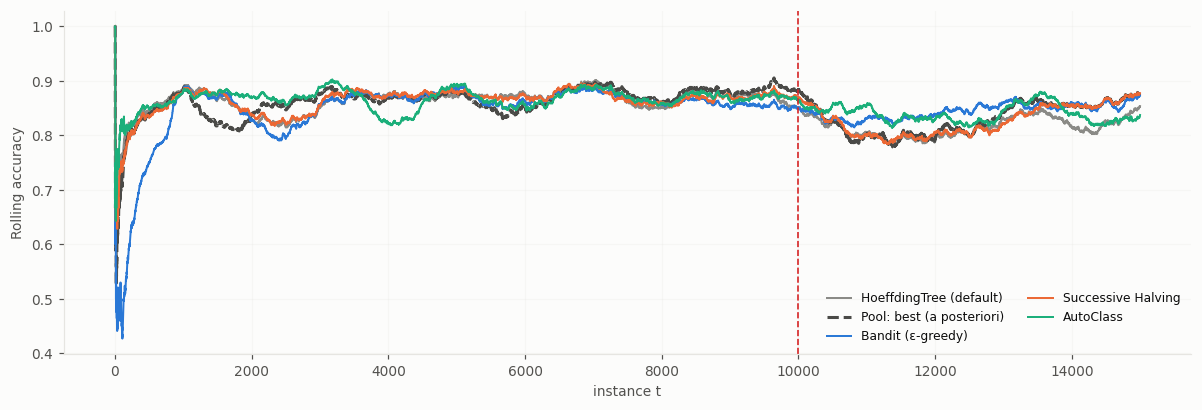

In [81]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for a in ["HoeffdingTree (default)", "Pool: best (a posteriori)", "Bandit (ε-greedy)", "Successive Halving", "AutoClass"]:
    ax.plot(auto_curves[("SEA+drift", a)], color=AUTO_COLORS[a], lw=2 if "Pool" in a else 1.3, label=a, ls="--" if "Pool" in a else "-")
ax.axvline(SEA_DRIFT, color="#d62728", ls="--", lw=1.1); ax.set_xlabel("instance t"); ax.set_ylabel("Rolling accuracy"); ax.legend(frameon=False, fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); savefig("fig28_automl_sea_curves")

In [82]:
# Automatic summary for the discussion (AutoML)
summ = auto_df.pivot(index="Approach", columns="Dataset", values="Accuracy").loc[APPROACHES].round(3)
print("Accuracy:"); display(summ)
print("Mean latency (ms per instance):"); display(auto_df.pivot(index="Approach", columns="Dataset", values="Mean latency (ms)").loc[APPROACHES].round(3))
print("Gap worst → best of the pool, in points:"); display(((summ.loc["Pool: best (a posteriori)"] - summ.loc["Pool: worst"]) * 100).round(1).to_frame("gap").T)

Accuracy:


Dataset,ImageSegments,Phishing,SEA+drift,Shuttle
Approach,,,,
HoeffdingTree (default),0.778,0.882,0.849,0.993
AdaptiveRF (10 trees),0.681,0.900,0.874,0.997
Pool: worst,0.778,0.851,0.829,0.982
Pool: median,0.783,0.875,0.850,0.992
Pool: best (a posteriori),0.881,0.883,0.855,0.994
Bandit (ε-greedy),0.780,0.878,0.853,0.992
Successive Halving,0.879,0.871,0.854,0.994
AutoClass,0.872,0.870,0.858,0.993


Mean latency (ms per instance):


Dataset,ImageSegments,Phishing,SEA+drift,Shuttle
Approach,,,,
HoeffdingTree (default),0.032,0.031,0.034,0.097
AdaptiveRF (10 trees),0.478,0.564,0.320,0.106
Pool: worst,0.038,0.167,0.087,0.087
Pool: median,0.179,0.033,0.082,0.031
Pool: best (a posteriori),0.101,0.231,0.053,0.117
Bandit (ε-greedy),13.094,7.744,8.775,7.446
Successive Halving,74.435,41.559,45.872,41.614
AutoClass,0.726,0.768,0.456,0.696


Gap worst → best of the pool, in points:


Dataset,ImageSegments,Phishing,SEA+drift,Shuttle
gap,10.300,3.200,2.600,1.200


### 10.2 Reading the results (AutoML)

**Does selection matter?** It depends on the dataset: the gap between the worst and the best model of the pool is **10.3 points on `ImageSegments`**, but only 3.2 (`Phishing`), 2.6 (`SEA+drift`) and 1.2 (`Shuttle`). The default tree equals the *worst* pool model on `ImageSegments` (0.778 vs 0.881 for the best).

- **`SuccessiveHalvingClassifier` recovers the best pool model where it matters:** 0.879 on `ImageSegments` (+10.1 points over the default tree, picking `kNN(k=3)`), and ties the best on `Shuttle` (0.994). On `Phishing` it is *below* the default tree (0.871 vs 0.882). **Its cost is extreme:** 42–74 ms per instance, i.e. **≈ 400–2,300× the default tree**, because all 15 models are trained.
- **`AutoClass` is the best compromise:** 0.872 on `ImageSegments`, and the best AutoML result on `SEA+drift` (0.858, Kappa 0.696), at 0.46–0.77 ms per instance, **≈ 55–100× cheaper than Successive Halving**. It is no better than the default tree on the easy datasets (`Phishing`, `Shuttle`).
- **`BanditClassifier` is the least convincing:** on `ImageSegments` it stays at 0.780 (≈ the default tree) because after the 100-instance burn-in it locked onto `HoeffdingTree(grace=50)` (also chosen on `Shuttle` and `SEA+drift`) instead of the much better `kNN`. It also costs 7–13 ms per instance (≈ 80–400× the default tree).
- **Under drift (figure 28):** all approaches dip after t = 10,000 and recover within a few thousand instances; the differences are small (a few points, one seed), with AutoClass and Bandit dipping slightly less than the default tree and Successive Halving.
- **Reference points outside the pool:** the 10-tree ARF is the best on `Phishing` (0.900), `Shuttle` (0.997) and `SEA+drift` (0.874), above every AutoML approach, but it is the worst on `ImageSegments` (0.681), where the pool's `kNN` wins. An AutoML is bounded by its pool.

* stream AutoML *selects*, it does not *create*. **Successive Halving = maximum quality, maximum cost; AutoClass = best quality/cost ratio; Bandit = cheap to set up but fragile.** The pool-best bar is an *a posteriori* bound, not an attainable result.

